## <a id='toc1_1_'></a>[Pricing a basket put option](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Pricing a basket put option](#toc1_1_)    
  - [Installing libraries](#toc1_2_)    
  - [Objective](#toc1_3_)    
  - [Importing libraries](#toc1_4_)    
- [1. Vanilla option](#toc2_)    
    - [Calibration inputs](#toc2_1_1_)    
    - [Option parameters](#toc2_1_2_)    
    - [Simulation inputs:](#toc2_1_3_)    
    - [Simulating the underlying dynamics for the vanilla put](#toc2_1_4_)    
  - [Getting vanilla option prices](#toc2_2_)    
- [2. Quanto single index option](#toc3_)    
  - [Additional pricing inputs for the quanto put SPX option:](#toc3_1_)    
    - [Correctly specifying the exhchange rate:](#toc3_1_1_)    
  - [Calibration inputs](#toc3_2_)    
  - [Option parameters](#toc3_3_)    
  - [Simulating the underlying dynamics for the quanto put](#toc3_4_)    
  - [Simulation inputs](#toc3_5_)    
  - [Simulating the underlying dynamics for the quanto put](#toc3_6_)    
    - [Impact of the correlation on the underlying forward price](#toc3_6_1_)    
  - [Getting quanto option prices](#toc3_7_)    
    - [Impact of correlation on the option price](#toc3_7_1_)    
  - [Quanto option via closed formula](#toc3_8_)    
- [Quanto basket option](#toc4_)    
  - [Underlying indices dynamics:](#toc4_1_)    
    - [EuroStoxx](#toc4_1_1_)    
    - [S&P 500](#toc4_1_2_)    
  - [Quanto basket pricing](#toc4_2_)    
    - [Calibration inputs](#toc4_2_1_)    
      - [Estimating USDEUR & SPX correlation using data until the previous valuation day Oct 14th 26:](#toc4_2_1_1_)    
    - [Option parameters](#toc4_2_2_)    
    - [Simulation inputs](#toc4_2_3_)    
    - [Simulating the underlying dynamics under EUR measure](#toc4_2_4_)    
    - [Getting quanto basket option prices](#toc4_2_5_)    
      - [DLIB comparison](#toc4_2_5_1_)    
        - [Comparison results](#toc4_2_5_1_1_)    
      - [DLIB Comparison inverting the reference curve](#toc4_2_5_2_)    
        - [Comparison results](#toc4_2_5_2_1_)    
        - [Check if price difference is explained by the basis on the discount rate](#toc4_2_5_2_2_)    
      - [Impact of correlation on the option price](#toc4_2_5_3_)    
    - [Pricing the basket calibrating on OVME data](#toc4_2_6_)    
      - [Option parameters](#toc4_2_6_1_)    
      - [Getting quanto basket option prices](#toc4_2_6_2_)    
  - [Basket composite pricing](#toc4_3_)    
    - [Nuances in the methodology](#toc4_3_1_)    
    - [Pricing using 3 factors](#toc4_3_2_)    
      - [Calibration inputs](#toc4_3_2_1_)    
        - [Estimating correlation matrix using data until the previous valuation day Oct 14th 26:](#toc4_3_2_1_1_)    
    - [Option parameters](#toc4_3_3_)    
    - [Simulation inputs](#toc4_3_4_)    
    - [Simulating the underlying dynamics under EUR measure](#toc4_3_5_)    
    - [Getting 3 factors option prices](#toc4_3_6_)    
    - [Explaining the difference between our price and the counterparty on the compo basket](#toc4_3_7_)    
      - [Option price sensitivity to implied correlations between indices and USDEUR](#toc4_3_7_1_)    
- [Conclusions](#toc5_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_2_'></a>[Installing libraries](#toc0_)

In [123]:
# run only if neeeded
# %pip install pandas
# %pip install datetime
# %pip install numpy
# %pip install matplotlib
# %pip install notebook nbconvert
# %pip install xbbg
# %pip install plotly
# %pip install scipy

## <a id='toc1_3_'></a>[Objective](#toc0_)

Pricing a european put basket option on SPX and EuroStoxx 600 on equity using different option types (with and without quanto adjustment on the foreign currency component). 

The primary objective is to replicate the price provided by the counterparty, next we also want to get a better understanding of: 
1. impact of correlation with the currency on the option price;
2. impact of the foreign currency on discounting e simluation taking into account the basis adjustment implied by the forward exchange rates. 

Since we want to replicate the prices of the counteparty we'll calibrate the pricing on their inputs whenever possible (volatilities, correlations and forwards).

The steps will be: 
1. Start from pricing a simple vanilla SPX ATM put;
2. Pricing a quanto SPX ATM put;
3. Evaluate the impact of correlation on the quanto put option;
4. Price a basket option where one index (SPX) is quanto adjusted. Basket value at expiryT $$ Basket_T= S1_T/S1_t * w1 + S2_T/S2_t * w2$$ $S1_T/S1_t$ is the SPX performance in USD (no impact of the currency in the payoff);
5. Price a basket option without any quanto adjustment. The performance of the SPX index is affected by currency risk and correlation impacting the final return for a EUR based investor.

## <a id='toc1_4_'></a>[Importing libraries](#toc0_)

In [124]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# <a id='toc2_'></a>[1. Vanilla option](#toc0_)
We assume to be pricing 1 year ATM put option on SPX Index as of 15-oct-2026 calibrating the pricing on the option price from the counterparty. 

Let's focus on the Vanilla first. 


### <a id='toc2_1_1_'></a>[Calibration inputs](#toc0_)
***Quotes from the counterparty:***
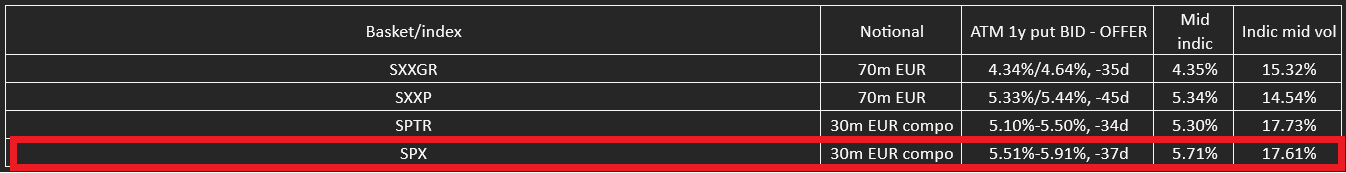


***Replicating the quote in OVME by forcing vol and price into the pricer***
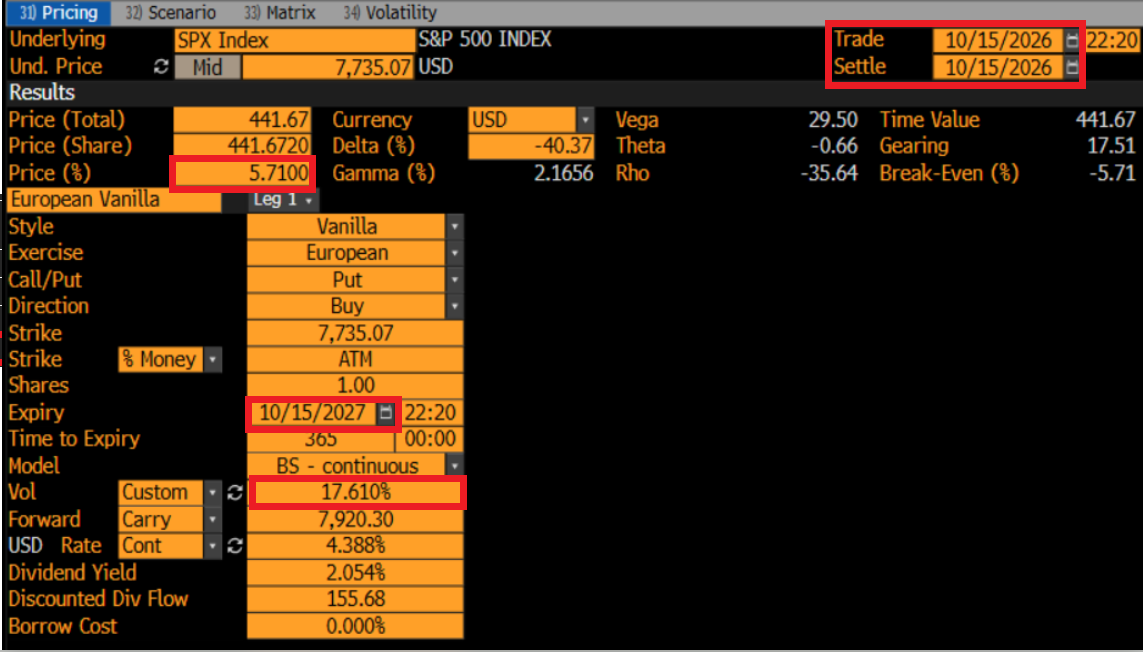

### <a id='toc2_1_2_'></a>[Option parameters](#toc0_)

In [125]:
## option parameters
T = 1 # time to maturity in years
moneyness = 1 
spot_price = 7_735.07
strike = moneyness * spot_price
r = 0.04388 # continuous risk-free rate USD
# disc_div = 29.18
fwd_OVME = 7920.30
price_put_vanilla_OVME = 441.6720
vol = 0.1761 # annual volatility in percentage
style = 'put'

### <a id='toc2_1_3_'></a>[Simulation inputs:](#toc0_)

In [126]:
# simulation inputs
sim_num = 1_000_000 # number of simulations
seed = 100

Getting useful quantities:

In [127]:

# use q implied by the forward, spot and risk-free rate, so we make sure to be simulating a disrtibution centered around the correct forward
q = r - 1/T * np.log(fwd_OVME/spot_price) # continuous dividend yield USD
theoretical_fwd = spot_price * np.exp((r - q) * T)

print(f"Spot price: {spot_price:.2f}")
print(f"Strike price: {strike:.2f}")
print("\nMaking sure the theoretical forward price is consistent with the OVME forward price:")
print(f"Forward price OVME: {fwd_OVME:.2f}")
print(f"Forward price recalculated S0*exp(mu*T): {theoretical_fwd:.2f}")
print(f"Risk-free rate: {r:.4%}")
print(f"Dividend yield: {q:.4%}")

Spot price: 7735.07
Strike price: 7735.07

Making sure the theoretical forward price is consistent with the OVME forward price:
Forward price OVME: 7920.30
Forward price recalculated S0*exp(mu*T): 7920.30
Risk-free rate: 4.3880%
Dividend yield: 2.0215%


### <a id='toc2_1_4_'></a>[Simulating the underlying dynamics for the vanilla put](#toc0_)

Price dynamics:
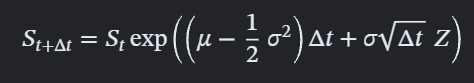

Price expectation at expiry (theoretical forward):
$$E[S_{t+\Delta t}] = S_t * exp(( r - q )  \Delta t )$$

where $\mu = r - q$.

In [128]:
# simulate standard normal random variables
def simulate_std_norm(sim_num, seed=None):
    rng_seeded = np.random.default_rng(seed=seed) # seed for reproducibility
    standard_normals = rng_seeded.standard_normal(sim_num).reshape(1, sim_num) # generate standard normal random variables
    # apply antithetic variates to reduce variance
    _W = np.concatenate((standard_normals, - standard_normals),axis=1) # combine standard normals and antithetic variates
    return _W

W = simulate_std_norm(sim_num, seed)

print("\nCheck shape of the combined standard normals and antithetic variates:")
print("Type of std_noise: " + str(type(W))) 
print("Shape of standard normals: " + str(W.shape)) # 1 row, 2*sim_num columns

# check anthithetic variates
print("\nStandard normals and antithetic variates, should be equal and opposite in sign:")
print(W[0, :5]) 
print(W[0, sim_num:(sim_num+5)])

# calculate simulated prices at expiry
mu = r - q # drift term
print(f"\nmu = {mu:.4%}")

def simulate_prices(spot_price, mu, vol, T, sim_num, seed=None):
    _W = simulate_std_norm(sim_num, seed)
    _fwd_sim_prices = spot_price * np.exp(  (mu - 1/2 * vol** 2) * T + vol * np.sqrt(T) * _W ) # forward prices at expiry
    return _fwd_sim_prices

fwd_sim_prices = simulate_prices(spot_price, mu, vol, T, sim_num, seed)

print("\nCheck forward prices:")
print("Shape of forward prices: " + str(fwd_sim_prices.shape))
print(f"First 5 simultated prices: {np.round(fwd_sim_prices[0, :5], 2)}")

print(f"\nTheoretical forward price: {theoretical_fwd:.4f}")
print(f"Mean of simulated forward price: {np.mean(fwd_sim_prices):.4f}")


Check shape of the combined standard normals and antithetic variates:
Type of std_noise: <class 'numpy.ndarray'>
Shape of standard normals: (1, 2000000)

Standard normals and antithetic variates, should be equal and opposite in sign:
[-1.15754965  0.2897558   0.78085407  0.54397364 -0.96138264]
[ 1.15754965 -0.2897558  -0.78085407 -0.54397364  0.96138264]

mu = 2.3665%

Check forward prices:
Shape of forward prices: (1, 2000000)
First 5 simultated prices: [6360.32 8206.69 8948.02 8582.43 6583.88]

Theoretical forward price: 7920.3000
Mean of simulated forward price: 7920.2900


## <a id='toc2_2_'></a>[Getting vanilla option prices](#toc0_)


In [129]:
def calc_vanilla_payoff(strike, spot_price, mu, vol, T, style='put', sim_num=100, seed=None):
    _fwd_sim_prices = simulate_prices(spot_price, mu, vol, T, sim_num, seed)
    if str.lower(style) == 'put': 
        _vanilla_payoffs = np.maximum(strike - _fwd_sim_prices, 0) # calculate payoffs for vanilla put option
    elif str.lower(style) == 'call': 
        _vanilla_payoffs = np.maximum(_fwd_sim_prices - strike, 0) # calculate payoffs for vanilla put option
    return _vanilla_payoffs

vanilla_put_payoffs = calc_vanilla_payoff(strike, spot_price, mu, vol, T, style, sim_num, seed)

print("\nCheck vanilla put undisconted payoffs average:")

def vanilla_option_pricer_MC(spot_price, mu, r, vol, T, strike, style, sim_num=100, seed=None):
    _vanilla_put_payoffs = calc_vanilla_payoff(strike, spot_price, mu, vol, T, style, sim_num, seed)
    print(np.round(np.mean(_vanilla_put_payoffs),4))
    _df = np.exp(-r * T) # discount factor 
    print(f"\nDiscount factor: {_df:.4f}")
    _put_vanilla_price = np.mean(_vanilla_put_payoffs) * _df
    return _put_vanilla_price

put_vanilla_price = vanilla_option_pricer_MC(spot_price, mu, r, vol, T, strike, style, sim_num, seed)

print(f"\nOption price (Share) USD: {np.round(put_vanilla_price,4)}")
print(f"Option price (%): {put_vanilla_price / spot_price:.4%}")

print(f"\nMy price vs OVME: {(put_vanilla_price / price_put_vanilla_OVME-1) * 10_000 :.2f} bps difference")



Check vanilla put undisconted payoffs average:
461.5938

Discount factor: 0.9571

Option price (Share) USD: 441.777
Option price (%): 5.7114%

My price vs OVME: 2.38 bps difference


In [130]:
# clear variables
mu = None
spot_price = None
r = None 
q = None 
vol = None 
T = None 
strike = None
style = None
sim_num = None 
seed = None 
moneyness = None 
fwd_OVME = None 
price_put_vanilla_OVME = None

# <a id='toc3_'></a>[2. Quanto single index option](#toc0_)
Now let's price the same put but with a quanto drift. Bloomberg doesn't handle quanto options. 

A common mistake is to simulate each index under its own measure (e.g., SPX with $r_{USD}$​, Euro Stoxx with $r_{EUR}$) and then discount the payoff in EUR. This is inconsistent.

In a Monte Carlo framework, the price is

$$V = DF \cdot \mathbb{E}^{Q}[\text{payoff}]$$

and this formula is valid only if all assets are simulated under the same measure, namely the one associated with the numeraire used for discounting.

For a quanto product, the payoff is denominated in EUR, so the relevant numeraire is the EUR cash account, i.e. the collateral curve (the €STR curve under an EUR CSA). Both the drift and the discounting must be consistent with that numeraire. Otherwise, the discounted asset prices are not martingales, and the resulting price is incorrect.


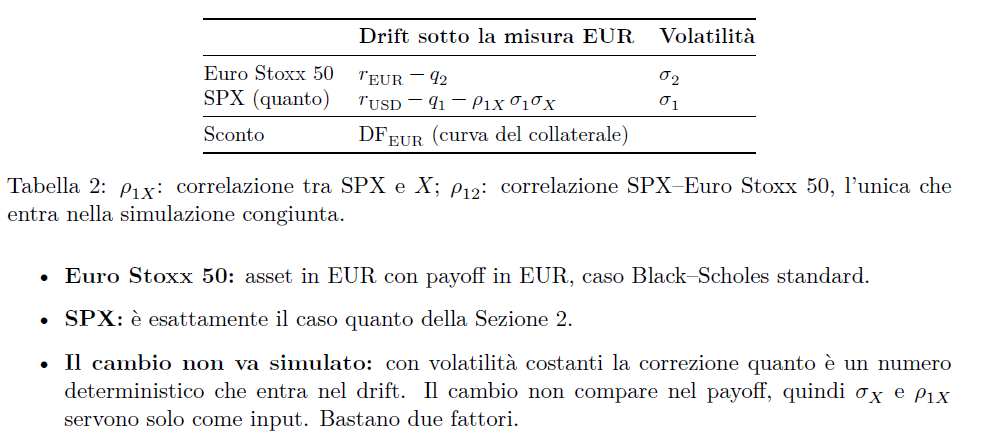
## <a id='toc3_1_'></a>[Additional pricing inputs for the quanto put SPX option:](#toc0_)
We need then some additional input: 
1. the correlation between the foreign index (SPX) and the forward exchange rate (USD);
2. the volatility of the of forward exchange rate between EUR and USD. 

### <a id='toc3_1_1_'></a>[Correctly specifying the exhchange rate:](#toc0_)
For the exchange rate, we consider ourselves to be EUR based investors who want to receive the option payment in EUR. 
We express the exchange rate X as the amount of EUR we can receive for each USD (the foreign currency is the base currency, or alternatively means you have to look at USDEUR Curny on Bloomberg). 

Why? 

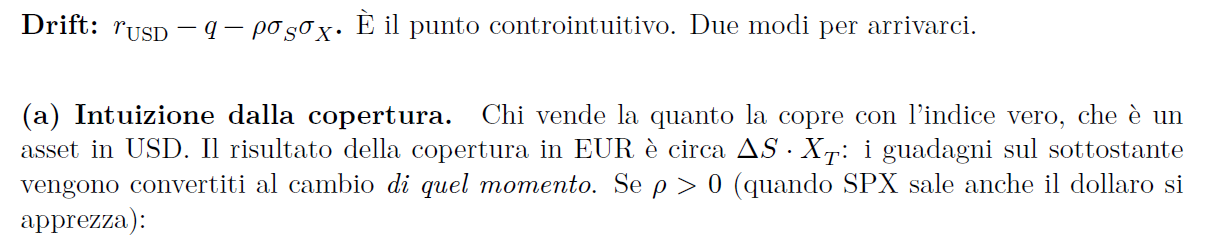
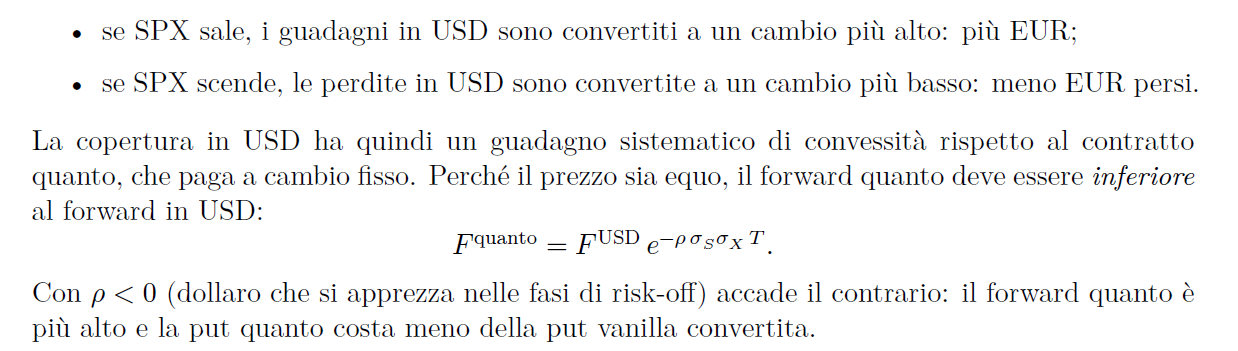
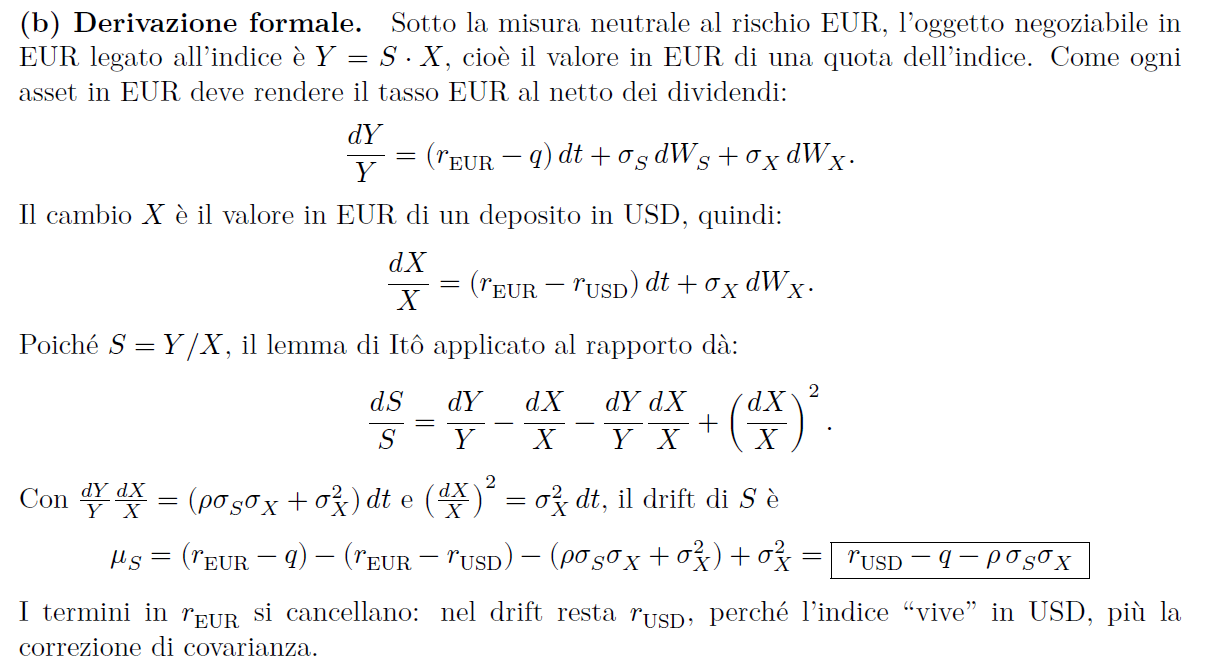

## <a id='toc3_2_'></a>[Calibration inputs](#toc0_)
We'll need some new inputs for the quanto option and we need some different inputs with respect to the vanilla: 
1. **correlation between SPX and USDEUR** (estimated from historical data);
2. **volatility of USDEUR**;
3. The **discount curve will be different** (not USD anymore), we discount under the EUR measure since we are pricing as EUR based investors. Notice: we'll still need the USD rate for the drift.

Let's take the EUR risk free from OVME, using the SXXP ATM put optin calibrated on the conuterparty volatility and price:

***Quotes from the counterparty:***
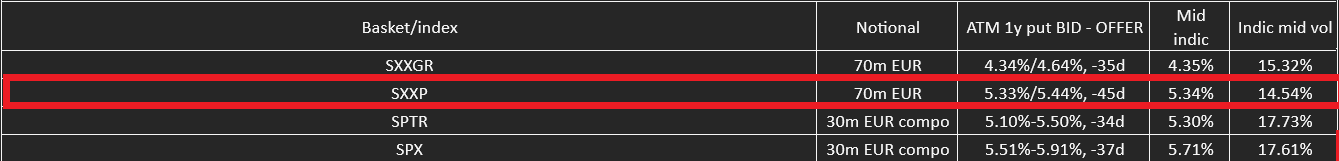

***Replicating the quote in OVME by forcing vol and price into the pricer***
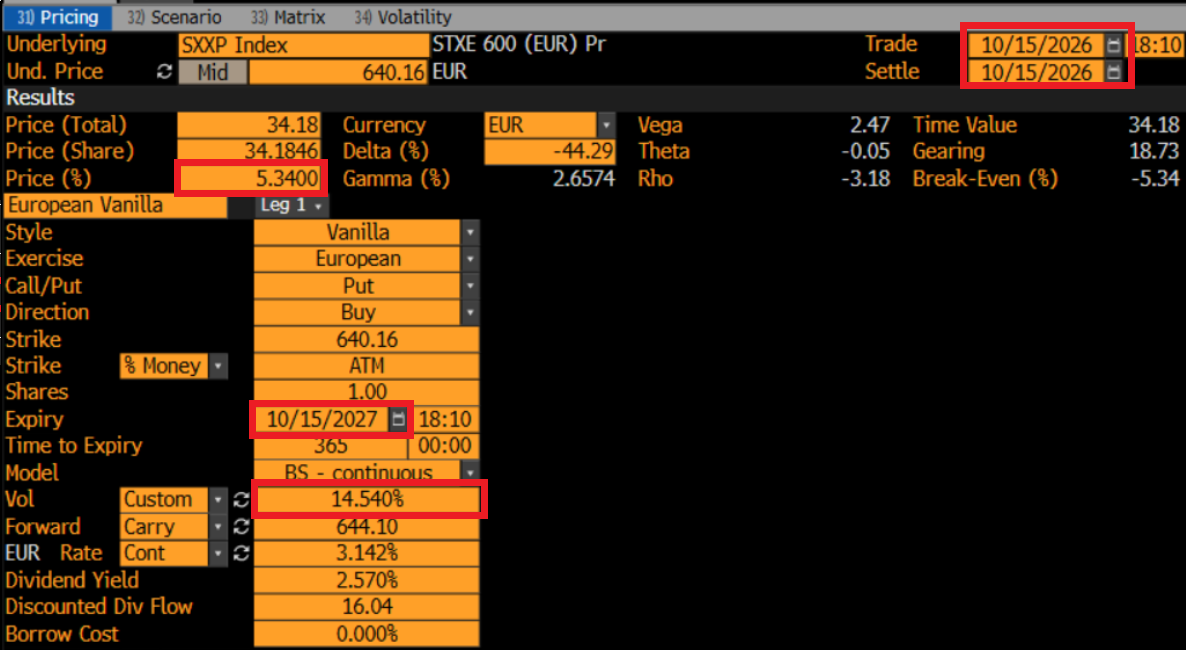

***FX vol from ATMF options with the same expiry date (no data provided by the counterparty on this)***

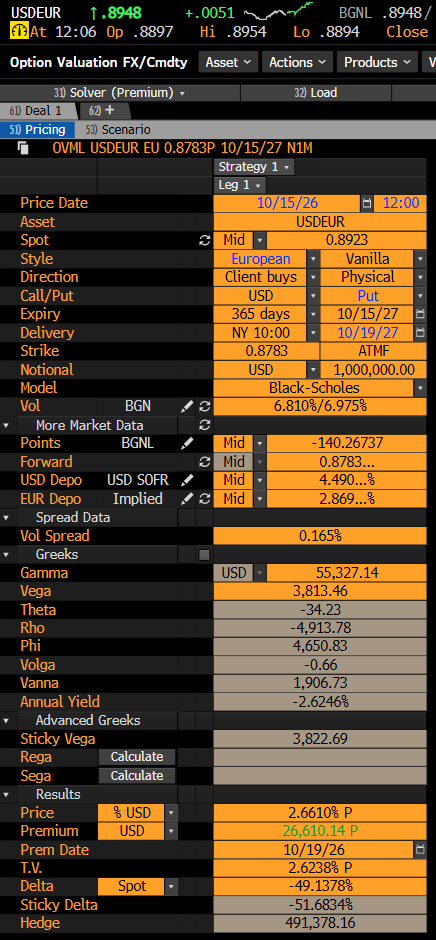

## <a id='toc3_3_'></a>[Option parameters](#toc0_)

In [131]:
## option parameters
T = 1 # time to maturity in years
moneyness = 1 
spot_price = 7_735.07
strike = moneyness * spot_price
r = 0.04388 # continuous risk-free rate USD for the drift (NOT DISCOUTING)
fwd_OVME = 7920.30
price_put_vanilla_OVME = 441.6720
vol = 0.1761 # annual volatility in percentage from the counterparty
style = 'put'

## define the new inputs under the EUR measure
r_disc = 0.03142 # continuous risk-free rate in EUR (used ONLY FOR DISCOUNTING)
rho = -0.30 # correlation between USD and SPX, rhough historical estimate
vol_fx = 0.068925 # mid vol from the screenshot

print(f"\nCorrelation between USD and SPX: {rho:.2f}")
print(f"FX vol: {vol_fx:.4%}")
print(f"SPX vol: {vol:.4%}")
print(f"USD-SPX correlation: {rho:.4%}")
print(f"Risk free in the drift: {r:.4%}")
print(f"Risk free for discounting: {r_disc:.4%}")


Correlation between USD and SPX: -0.30
FX vol: 6.8925%
SPX vol: 17.6100%
USD-SPX correlation: -30.0000%
Risk free in the drift: 4.3880%
Risk free for discounting: 3.1420%


Getting useful quantities:

In [132]:
# use q implied by the forward, spot and risk-free rate
q = r - 1/T * np.log(fwd_OVME/spot_price) # continuous dividend yield USD
theoretical_fwd = spot_price * np.exp((r - q) * T)

mu = r - q # drift term

print(f"\nmu = {mu:.4%}")
print(f"Spot price: {spot_price:.2f}")
print(f"Strike price: {strike:.2f}")
print("\nMaking sure the theoretical forward price is consistent with the OVME forward price:")
print(f"Forward price OVME: {fwd_OVME:.2f}")
print(f"Forward price recalculated S0*exp(mu*T): {theoretical_fwd:.2f}")
print(f"Risk-free rate: {r:.4%}")
print(f"Dividend yield: {q:.4%}")


mu = 2.3665%
Spot price: 7735.07
Strike price: 7735.07

Making sure the theoretical forward price is consistent with the OVME forward price:
Forward price OVME: 7920.30
Forward price recalculated S0*exp(mu*T): 7920.30
Risk-free rate: 4.3880%
Dividend yield: 2.0215%


## <a id='toc3_4_'></a>[Simulating the underlying dynamics for the quanto put](#toc0_)

Price dynamics are the same with the adjustment on the drift:

$$S_{t+\Delta t}=S_t\exp\left(\left(r_{USD}-q-\rho\sigma_S\sigma_X-\frac{1}{2}\sigma_S^2\right)\Delta t+\sigma_S\sqrt{\Delta t}\,Z_S\right)$$

Price expectation at expiry (theoretical forward):


$$E[S_{t+\Delta t}] = S_0 * exp(( r_{USD} - q - \rho \sigma_S \sigma_X)  \Delta t )$$


## <a id='toc3_5_'></a>[Simulation inputs](#toc0_)

In [133]:
# simulation inputs
sim_num = 1_000_000 # number of simulations
seed = 100

## <a id='toc3_6_'></a>[Simulating the underlying dynamics for the quanto put](#toc0_)

In [134]:
# simulate standard normal random variables
W = simulate_std_norm(sim_num, seed)

## ADJUSTED DRIFT TERM FOR CORRELATION BETWEEN USD AND SPX, ALL THE REST IS THE SAME AS THE VANILLA PUT PRICING
mu_quanto = mu - rho*vol*vol_fx # drift term is adjusted for correlation between USD and SPX
print(f"mu quanto adjusted = {mu_quanto:.4%}")
fwd_sim_prices = simulate_prices(spot_price, mu_quanto,vol,T,sim_num,seed)

theoretical_fwd_quanto = spot_price * np.exp((mu_quanto) * T)

print("\nCheck forward prices:")
print("Shape of forward prices: " + str(fwd_sim_prices.shape))
print(f"First 5 simultated prices: {np.round(fwd_sim_prices[0, :5], 2)}")

print(f"\nTheoretical quanto forward price: {theoretical_fwd_quanto:.4f}")
print(f"Mean of simulated quanto forward price: {np.mean(fwd_sim_prices):.4f}")

mu quanto adjusted = 2.7306%

Check forward prices:
Shape of forward prices: (1, 2000000)
First 5 simultated prices: [6383.52 8236.63 8980.66 8613.74 6607.9 ]

Theoretical quanto forward price: 7949.1928
Mean of simulated quanto forward price: 7949.1828


### <a id='toc3_6_1_'></a>[Impact of the correlation on the underlying forward price](#toc0_)

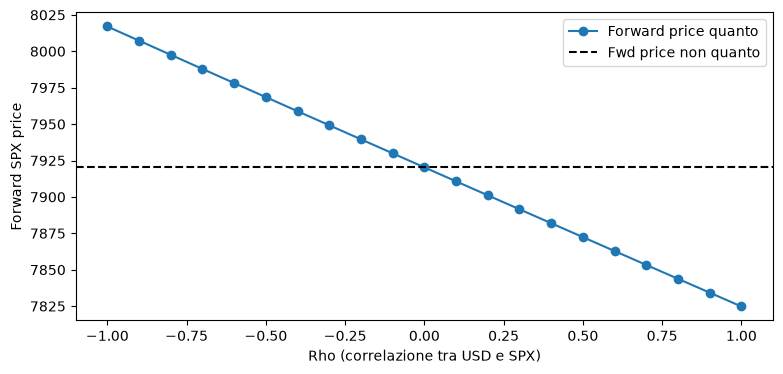

In [135]:
quanto_fwd_plot = []
rho_range = np.arange(-1, 1.1, 0.1)

for rho_i in rho_range:
    mu_quanto_i = mu - rho_i*vol*vol_fx # drift term is adjusted for correlation between USD and SPX
    theoretical_fwd_quanto_plot = spot_price * np.exp((mu_quanto_i) * T)
    quanto_fwd_plot.append(theoretical_fwd_quanto_plot)

# Visualizziamo la variazione nel fwd al variare della correlazione tra USD e SPX
plt.figure(figsize=(9, 4))
plt.plot(rho_range, quanto_fwd_plot, marker='o', label='Forward price quanto')
plt.axhline(spot_price * np.exp(mu * T), color='black', linestyle='--', label='Fwd price non quanto')
plt.xlabel('Rho (correlazione tra USD e SPX)')
plt.ylabel('Forward SPX price')
plt.legend()
plt.show()


## <a id='toc3_7_'></a>[Getting quanto option prices](#toc0_)

In [136]:
quanto_put_payoffs = calc_vanilla_payoff(strike, spot_price, mu_quanto, vol, T, style, sim_num, seed)

print(f"Quanto mean undiscoutned payoffs are {np.round(np.mean(quanto_put_payoffs),4)}\n vs \nVanilla mean undiscoutned payoffs are {np.round(np.mean(vanilla_put_payoffs),4)}")

df = np.exp(-r_disc * T) # discount factor does not change, it is still based on the risk-free rate
print(f"\nDiscount factor in EUR {df}")
put_quanto_price = np.mean(quanto_put_payoffs) * df

print(f"\nQuanto option price (Share) USD: {np.round(put_quanto_price,4)}")
print(f"Vanilla option price (Share) USD: {np.round(put_vanilla_price,4)}")

print(f"\nQuanto option price (%): {put_quanto_price / spot_price:.2%}")
print(f"Vanilla option price (%): {put_vanilla_price / spot_price:.2%}")


Quanto mean undiscoutned payoffs are 449.81
 vs 
Vanilla mean undiscoutned payoffs are 461.5938

Discount factor in EUR 0.9690684788311097

Quanto option price (Share) USD: 435.8967
Vanilla option price (Share) USD: 441.777

Quanto option price (%): 5.64%
Vanilla option price (%): 5.71%


### <a id='toc3_7_1_'></a>[Impact of correlation on the option price](#toc0_)

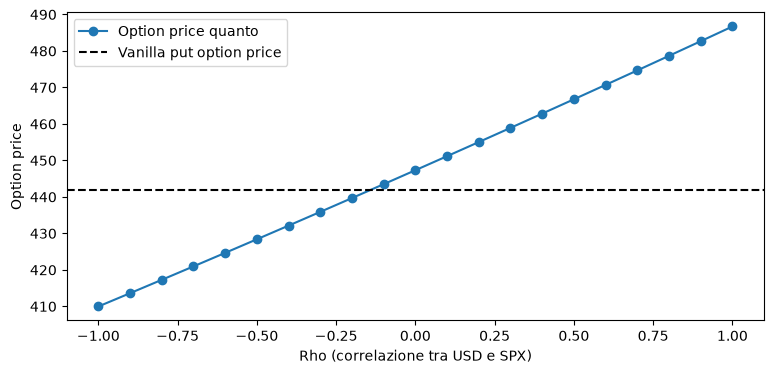

In [137]:
quanto_price_plot = []
rho_range = np.arange(-1, 1.1, 0.1)

for rho_i in rho_range:
    mu_quanto_i = mu - rho_i*vol*vol_fx # drift term is adjusted for correlation between USD and SPX
    fwd_sim_prices = spot_price * np.exp(  (mu_quanto_i - 1/2 * vol** 2) * T + vol * np.sqrt(T) * W ) # forward prices at expiry
    quanto_price = df * np.mean(np.maximum(strike - fwd_sim_prices, 0)) # calculate option price for quanto put option
    quanto_price_plot.append(quanto_price)

# Visualizziamo la variazione nel fwd al variare della correlazione tra USD e SPX
plt.figure(figsize=(9, 4))
plt.plot(rho_range, quanto_price_plot, marker='o', label='Option price quanto')
plt.axhline(put_vanilla_price, color='black', linestyle='--', label='Vanilla put option price')
plt.xlabel('Rho (correlazione tra USD e SPX)')
plt.ylabel('Option price')
plt.legend()
plt.show()


## <a id='toc3_8_'></a>[Quanto option via closed formula](#toc0_)

In [138]:
def bs_closed_form_eu_quanto(style, strike, T, r_disc, F_q, vol):   
    """
    F_q = forward quanto adjusted
    """
    # Validate option type
    if style not in ["C", "P", "call", "put"]:
        raise ValueError("Invalid option type. Use 'C' or 'call' for call or 'P' or 'put' for put.")

    # Validate numeric inputs
    if spot_price <= 0 or strike <= 0 or vol <= 0:
        raise ValueError("Inputs `S`, `K`, `sigma` must be positive and `dy` must be non-negative.")

    # Define the cumulative distribution function of the standard normal
    N = norm.cdf

    # Precompute terms
    sqrt_T = np.sqrt(T)
    exp_neg_r_T = np.exp(-r_disc * T)

    # Compute d1 and d2
    d1 = ((np.log(F_q / strike) + vol ** 2 / 2) * T) / (vol * sqrt_T)
    d2 = d1 - vol * sqrt_T

    # Compute the option price
    price = None
    if style == "C" or style == "call":
        price = exp_neg_r_T * (F_q * N(d1) - strike * N(d2))
    elif style == "P" or style == 'put':
        price = exp_neg_r_T * (strike *   N(-d2) - F_q * N(-d1))

    return price

quanto_put_closed = bs_closed_form_eu_quanto(style, strike, T, r_disc, theoretical_fwd_quanto, vol)

print(f"Quanto option price (Share) USD via cloed formula {quanto_put_closed:.4f}")
print(f"\nQuanto option price (Share) USD via MC: {np.round(put_quanto_price,4)}")



Quanto option price (Share) USD via cloed formula 435.8389

Quanto option price (Share) USD via MC: 435.8967


In [139]:
# clear variables
mu = None
spot_price = None
r = None 
q = None 
vol = None 
T = None 
strike = None
style = None
sim_num = None 
seed = None 
moneyness = None 
fwd_OVME = None 
price_put_vanilla_OVME = None
rho = None
rho_i = None
mu_quanto = None
mu_quanto_i = None

# <a id='toc4_'></a>[Quanto basket option](#toc0_)
Let's now price a basket option, where the indices priced in foreign currency (USD) are quanto adjusted. We'll consider a basket made of the SPX index and the SXXP index, with weights 30% and 70% respectively. 

The option payoff will be based on the performance of the basket and the value of the basket at expiry T is calculated as follows: $$ Basket_T= S1_T/S1_t * w1 + S2_T/S2_t * w2$$ $S1_T/S1_t$ is the SPX performance in USD (no impact of the the foreign currency in the basket performance). 

In this setting we'll be using the EUR measure, since we'll be discounting in EUR. So let's define the dynamics of the underlying assets of the basket.

## <a id='toc4_1_'></a>[Underlying indices dynamics:](#toc0_)
We'll let the underlying evolve under the EUR measure and we'll also need to link the dynamics of the indices to their correlation. 

### <a id='toc4_1_1_'></a>[EuroStoxx](#toc0_)
Nothing changes for the EuroStoxx, the index is expressed in EUR and we are pricing in EUR, so it's a plain vanilla setting. 

EuroStoxx dynamics:
$$S_{t+\Delta t} = S_t \exp((r_{EUR}-q-1/2\sigma^2)\Delta t + \sigma \sqrt{\Delta t}Z_1 )$$

Price expectation at expiry (theoretical forward):
$$E[S_{t+\Delta t}] = S_t exp((r_{EUR}-q)  \Delta t )$$

Notice: 
$Z_1$ is the standard normal noise, the correlation between the two indices is captured within this term. 

So when we simulate the standard normal to generate the diffusion component we need generate two correlated standard normal random variables $Z_1$ and $Z_2$. 

### <a id='toc4_1_2_'></a>[S&P 500](#toc0_)
The S&P 500 is an index expressed in USD, so we need to apply the quanto adjustment on its dynamics if we want to let it evolve under the EUR measure, so that we can discount it using the EUR curve. The drift will include the quanto adjustement. 

S&P 500 dynamics:
$$S_{t+\Delta t} = S_t \exp((r_{USD}-q - \rho \sigma_S \sigma_X -1/2\sigma^2)\Delta t + \sigma \sqrt{\Delta t}Z_2 )$$

Price expectation at expiry (theoretical forward):
$$E[S_{t+\Delta t}] = S_t exp((r_{USD}-q - \rho \sigma_S \sigma_X -1/2\sigma^2)  \Delta t )$$

where: 
- $\rho$ = correlation between S&P 500 and USDEUR pair (expressed as amount of Euros per unit of US Dollars, i.e. USD as a base, EUR as price currency)
- $\sigma_S$ = constant vol of the S&P 500
- $\sigma_X$ = constant vol of USDEUR

We model USDEUR and not EURUSD (Bloomberg syntax convetion is used here) since this is the quantity to multiple if we want to convert an amount from USD to EUR. e.g. 100 USD, 1 USD = 0.83 EUR or USDEUR = 0.83 then 100 USD * 0.83 = 83 EUR.

Notice: 
$Z_2$ is the standard normal noise, the correlation between the two indices is captured within this term. 

So when we simulate the standard normal to generate the diffusion component we need generate two correlated standard normal random variables $Z_1$ and $Z_2$. 

See derivation below:

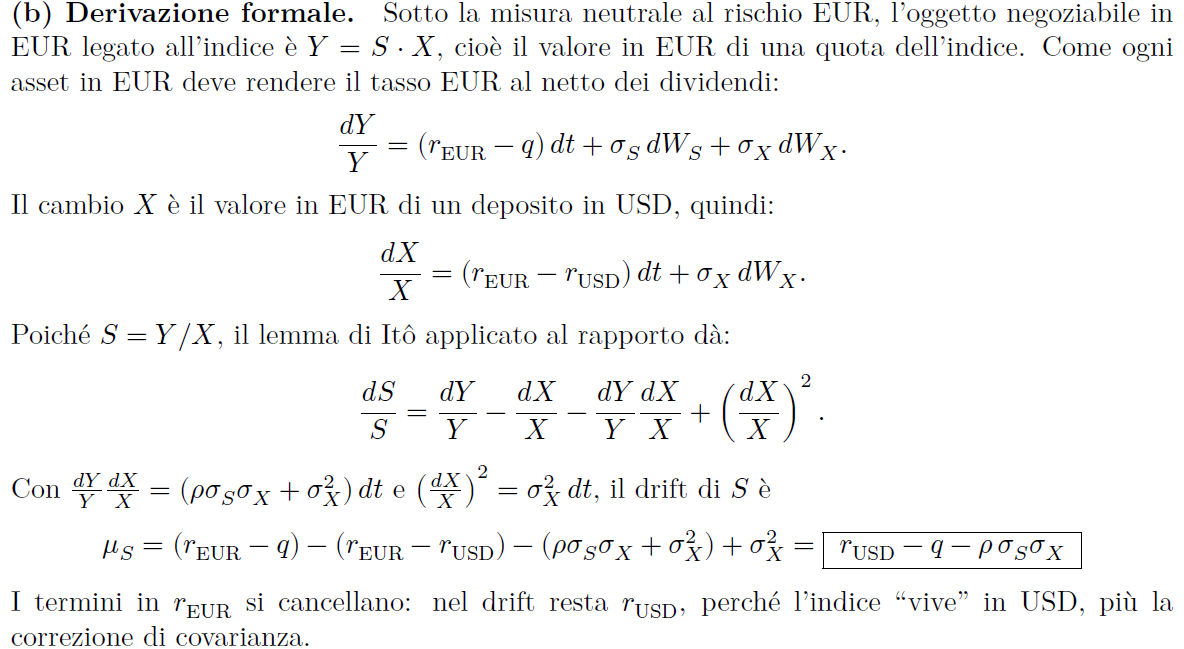

## <a id='toc4_2_'></a>[Quanto basket pricing](#toc0_)

### <a id='toc4_2_1_'></a>[Calibration inputs](#toc0_)
We assume to be pricing a 1 year ATM put option on a basket composed of the SPX Index and SXXP Index as of 15-oct-2026 where the SPX component is quanto adjusted.

The weights are: 
- $w_1 = w_{sxxp} $
- $w_2 = w_{spx} $ 

and the value at expiry of the basket is calculated as follows: 
$$Basket_T= S^1_T/S^1_t * w_1 + S^2_T/S^2_t * w_2$$

Notice: 
- there is no weight rebalancing on the basket;
- there is no impact from the currency the basket performance.

Where possible we'll use inputs given from a counterparty in order to match their price on the basket option and price in consistency with the pricing of the single index options priced ealier: 

- From the counterparty we use:
    - Implied vol of the indices
    - Implied correlation between indices
    - Single index put option prices to infer the forward price

    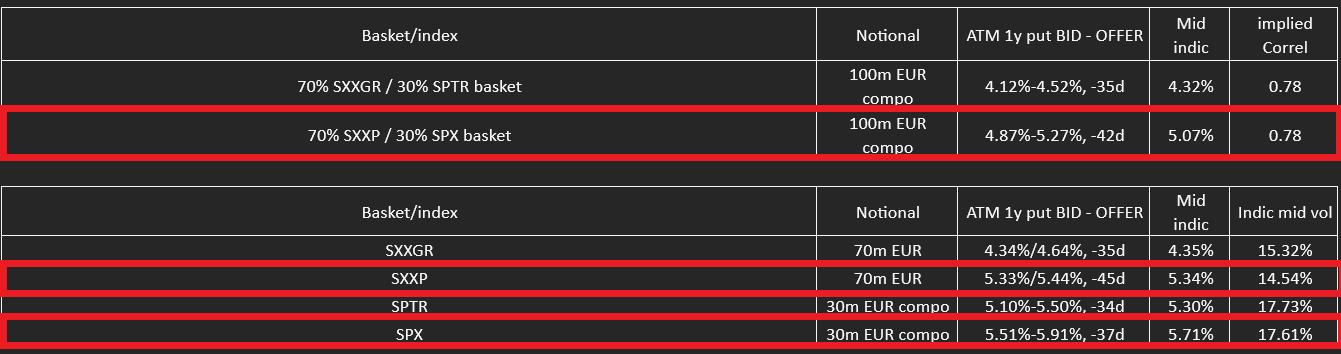

- From OVME we get:
    - risk free in EUR and USD
    - forward index level implied by the counterparty option price and vols on single index options
        
        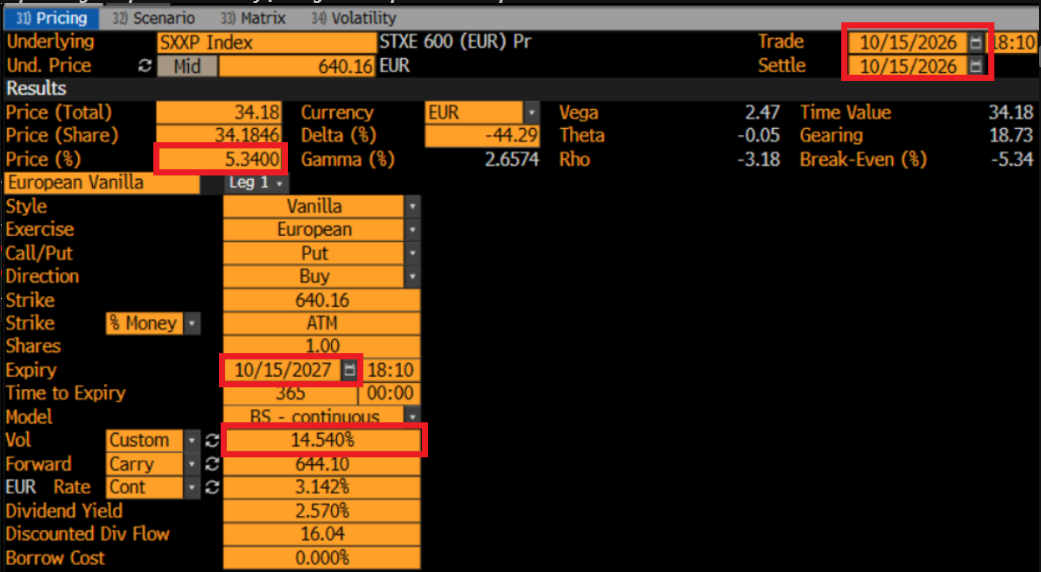

        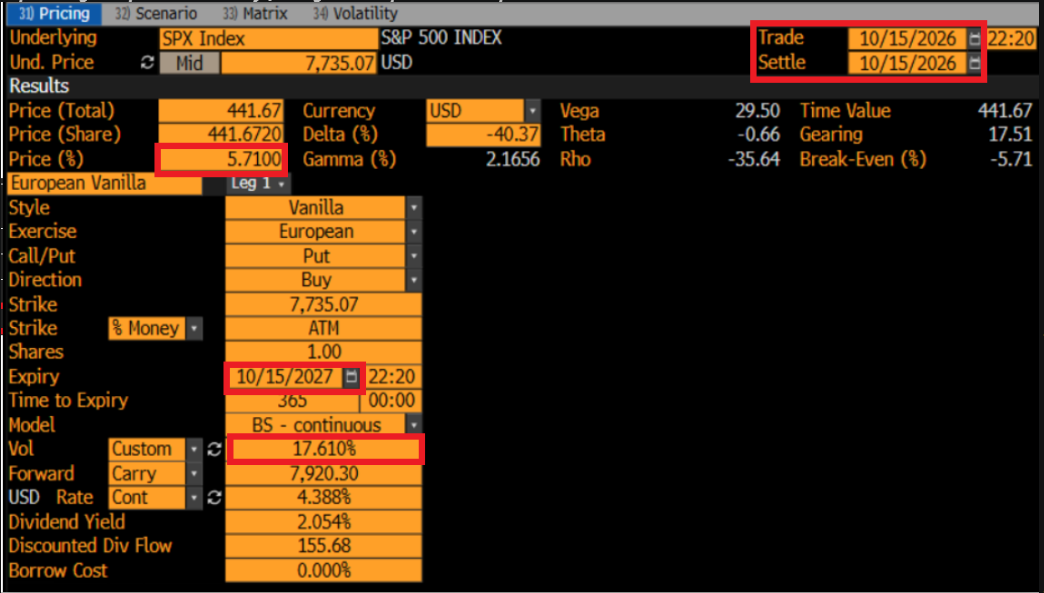](attachment:image-2.png)

- Exchange rate vol is taken from Bloomberg OVML USDEUR 1Y ATMF option (not provided by the counterparty; we use the ATM FORWARD implied vol since it centered in the forward distribution, notice that it doesn't impact directly the return of the basket in the quanto option, it enters only via the quanto drift adjustment);

    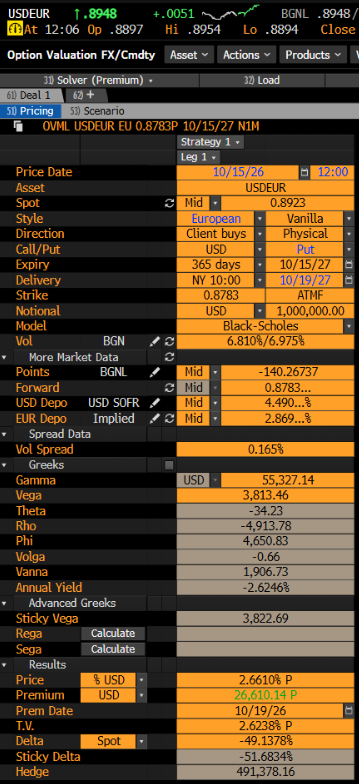

- For the correlation between SPX and USDEUR we use an historical estimate done in the following section. Estimate has been done on different lookbacks and the 1Y daily estimate has been used for pricing.

#### <a id='toc4_2_1_1_'></a>[Estimating USDEUR & SPX correlation using data until the previous valuation day Oct 14th 26:](#toc0_)

In [140]:
import pandas as pd
from xbbg import blp

In [141]:
# tickers to download
tickers = ['SPX Index', 'EUUS F160 Curncy']

# Lookback data
start_date = pd.to_datetime('20161014')
end_date = pd.to_datetime('20261014')
currency = "None"
field = "PX_LAST"

Dowload and clean the data via Bloomberg python blp.bdh

In [142]:
# download raw data
try: 
    raw_df = blp.bdh(tickers, field, start_date, end_date, currency = currency).to_native()
    time_series = pd.DataFrame(columns=['date'])
except: 
    print("currency= None, using bdh formula without currency")
    raw_df = blp.bdh(tickers, field, start_date, end_date).to_native()
    time_series = pd.DataFrame(columns=['date'])

currency= None, using bdh formula without currency


In [143]:
# tidy up and clean the data
for ticker in tickers:
    filtered_df = raw_df[raw_df['ticker'] == ticker].drop(columns=['ticker', 'field'])
    filtered_df = filtered_df.rename(columns={'value': ticker}).copy()

    time_series = pd.merge(time_series, filtered_df, how = 'outer', on = 'date')

time_series.index = pd.to_datetime(time_series['date'])
time_series.drop(columns = 'date', inplace = True)

# remove dates if any assets are in holiday for a given date (avoid using stale observations to calculate log returns)
time_series.dropna(how='any', inplace = True)
time_series.to_csv('SPX&USDEUR.csv')

# sort dates descending
time_series.sort_index(axis=0, ascending=False, inplace=True)

print("Some info on the dataframe:")
print('\n')
print('Head')
print(time_series.head())
print('Tail')
print(time_series.tail())
print('\n')
print('Describe')
print(time_series.describe())
print('\n')
print('Info')
print(time_series.info())


Some info on the dataframe:


Head
            SPX Index  EUUS F160 Curncy
date                                   
2026-10-14    7718.94            0.8964
2026-10-13    7805.45            0.8930
2026-10-12    7807.24            0.8965
2026-10-09    7811.54            0.8929
2026-10-08    7765.36            0.8918
Tail
            SPX Index  EUUS F160 Curncy
date                                   
2016-10-20    2141.34            0.9152
2016-10-19    2144.29            0.9116
2016-10-18    2139.60            0.9107
2016-10-17    2126.50            0.9088
2016-10-14    2132.98            0.9114


Describe
         SPX Index  EUUS F160 Curncy
count  2513.000000       2513.000000
mean   4178.798082          0.891504
std    1499.169129          0.043944
min    2085.180000          0.799000
25%    2850.960000          0.855900
50%    3981.350000          0.888700
75%    5157.360000          0.922100
max    7818.930000          1.042500


Info
<class 'pandas.DataFrame'>
DatetimeIndex: 2513 en

Get weekly data

In [144]:
# resample weekly prices on a Friday or last available price
time_series_weekly = time_series.resample("W-FRI").last().sort_index(ascending=False)
# drop first or last observation if first and last dates are not on Friday to avoid using a shorter period of time
if time_series.index[0].day_name() != 'Friday': 
    time_series_weekly = time_series_weekly.iloc[1:]
elif time_series.index[-1].day_name():
    time_series_weekly = time_series_weekly.iloc[:-1]

print("Some info on the weekly prices:")
print('\n')
print('Head')
print(time_series_weekly.head())
print('Tail')
print(time_series_weekly.tail())
print('\n')
print('Describe')
print(time_series_weekly.describe())
print('\n')
print('Info')
print(time_series_weekly.info())


Some info on the weekly prices:


Head
            SPX Index  EUUS F160 Curncy
date                                   
2026-10-09    7811.54            0.8929
2026-10-02    7722.72            0.8884
2026-09-25    7743.41            0.8775
2026-09-18    7650.50            0.8706
2026-09-11    7656.98            0.8624
Tail
            SPX Index  EUUS F160 Curncy
date                                   
2016-11-11    2164.45            0.9219
2016-11-04    2085.18            0.8979
2016-10-28    2126.41            0.9104
2016-10-21    2141.16            0.9191
2016-10-14    2132.98            0.9114


Describe
         SPX Index  EUUS F160 Curncy
count   522.000000        522.000000
mean   4176.460517          0.891606
std    1498.428687          0.043992
min    2085.180000          0.802500
25%    2852.480000          0.856150
50%    3983.735000          0.889800
75%    5126.765000          0.922700
max    7811.540000          1.031700


Info
<class 'pandas.DataFrame'>
DatetimeIndex: 522

Get log returns and estimate correlation. 

Daily:

In [145]:
# get log returns for each asset
log_ret_d = np.log(time_series / time_series.shift(-1))
# remove first obs NA
log_ret_d.dropna(inplace=True)

print("Some info on the Daily log ret:")
print('\n')
print('Describe')
print(log_ret_d.describe())
print('\n')
print('Info')
print(log_ret_d.info())
print('\n')
print('Head')
print(log_ret_d.head())
print('Tail')
print(log_ret_d.tail())

Some info on the Daily log ret:


Describe
         SPX Index  EUUS F160 Curncy
count  2512.000000       2512.000000
mean      0.000512         -0.000007
std       0.011414          0.004527
min      -0.127652         -0.022908
25%      -0.003764         -0.002729
50%       0.000763          0.000000
75%       0.005876          0.002723
max       0.090895          0.020388


Info
<class 'pandas.DataFrame'>
DatetimeIndex: 2512 entries, 2026-10-14 to 2016-10-17
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SPX Index         2512 non-null   float64
 1   EUUS F160 Curncy  2512 non-null   float64
dtypes: float64(2)
memory usage: 58.9 KB
None


Head
            SPX Index  EUUS F160 Curncy
date                                   
2026-10-14  -0.011145          0.003800
2026-10-13  -0.000229         -0.003912
2026-10-12  -0.000551          0.004024
2026-10-09   0.005929          0.001233
2026-10-08  -0.004678  

Weekly:

In [146]:
# get log returns for each asset
log_ret_w = np.log(time_series_weekly / time_series_weekly.shift(-1))
# remove first obs NA
log_ret_w.dropna(inplace=True)

print("Some info on the Daily log ret:")
print('\n')
print('Describe')
print(log_ret_w.describe())
print('\n')
print('Info')
print(log_ret_w.info())
print('\n')
print('Head')
print(log_ret_w.head())
print('Tail')
print(log_ret_w.tail())

Some info on the Daily log ret:


Describe
        SPX Index  EUUS F160 Curncy
count  521.000000        521.000000
mean     0.002492         -0.000039
std      0.023881          0.009842
min     -0.162279         -0.044551
25%     -0.008955         -0.005616
50%      0.003946          0.000199
75%      0.015039          0.006140
max      0.114237          0.039494


Info
<class 'pandas.DataFrame'>
DatetimeIndex: 521 entries, 2026-10-09 to 2016-10-21
Freq: -1W-FRI
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SPX Index         521 non-null    float64
 1   EUUS F160 Curncy  521 non-null    float64
dtypes: float64(2)
memory usage: 12.2 KB
None


Head
            SPX Index  EUUS F160 Curncy
date                                   
2026-10-09   0.011435          0.005053
2026-10-02  -0.002676          0.012345
2026-09-25   0.012071          0.007894
2026-09-18  -0.000847          0.009463
2026-09-11  -0.0080

In [147]:
# estimate correlations
# Daily freq
print("Correlation estimates on DAILY frequency data:")
last_date = log_ret_d.index.max()
for lookback in [1,2,5,10]: 
    lookback_start = last_date - pd.DateOffset(years=lookback)
    print(f"{lookback}Y corr: {np.round(log_ret_d.loc[log_ret_d.index >= lookback_start].corr()[tickers[0]][tickers[1]],2)}")

# weekly freq
print("\nCorrelation estimates on WEEKLY frequency data:")
last_date = log_ret_d.index.max()
for lookback in [1,2,5,10]: 
    lookback_start = last_date - pd.DateOffset(years=lookback)
    print(f"{lookback}Y corr: {np.round(log_ret_w.loc[log_ret_w.index >= lookback_start].corr()[tickers[0]][tickers[1]],2)}")



Correlation estimates on DAILY frequency data:
1Y corr: -0.33
2Y corr: -0.02
5Y corr: -0.25
10Y corr: -0.14

Correlation estimates on WEEKLY frequency data:
1Y corr: -0.31
2Y corr: -0.13
5Y corr: -0.34
10Y corr: -0.31


### <a id='toc4_2_2_'></a>[Option parameters](#toc0_)

In [148]:
## option parameters
T = 1 # time to maturity in years
weights = np.array([0.7, 0.3]) # weights for SXXP and SXP 
S_0 = np.array([640.16, 7_735.07])
num_assets = len(S_0)
S_0 = S_0.reshape(num_assets,1) # spot at valuation date for SXXP and SXP
strike = 1 # strike expressed in decimal as multiplier of the basket value at inception
r = np.array([0.03142, 0.0488]).reshape(num_assets,1)  # continuous risk-free rate EUR and USD
r_disc = 0.03142 # discounting using the EUR curve
fwd_OVME = np.array([644.10, 7_920.30]).reshape(num_assets,1) 
vol_idx = np.array([0.1454, 0.1761]).reshape(num_assets,1) # annual implied volatility in percentage taken from counterparty quotes
vol_fx = 0.068925 # mid vol from the screenshot
corr_spx_usd = -0.31 # using the 1Y daily historical correlation between USDEUR and SPX
corr_idx = 0.78 # implied correlation between SXXP and SXP, taken from counterparty quotes
style = 'put'
basket_price_cpty = 0.0507

corr_idx_m = np.array([[1, corr_idx], [corr_idx,1]]) # correlation matrix, used for simulating normal correlated random variables

print(f"Correlation matrix for the two indices:\n {corr_idx_m}")
print(f"\nCorrelation between SPX and USD:\n{corr_spx_usd}")
print(f"Risk free rates: {r}")
print(f"FX vol: {vol_fx}")
print(f"Basket option price from counterparty:{basket_price_cpty}")

Correlation matrix for the two indices:
 [[1.   0.78]
 [0.78 1.  ]]

Correlation between SPX and USD:
-0.31
Risk free rates: [[0.03142]
 [0.0488 ]]
FX vol: 0.068925
Basket option price from counterparty:0.0507


Getting useful quantities: 

In [149]:
# use q implied by the forward, spot and risk-free rate
q = r - 1/T * np.log(fwd_OVME/S_0) # vector of continuous dividend yields USD 
theoretical_fwd = S_0 * np.exp((r - q) * T) # vector of theoretical forward prices for SXXP and SXP (identical to OVME forward prices by construction)
## ADJUSTED DRIFT TERM FOR CORRELATION BETWEEN USD AND SPX, ALL THE REST IS THE SAME AS THE VANILLA PUT PRICING
mu_quanto = r[1,0] - q[1,0] - corr_spx_usd*vol_idx[1,0]*vol_fx # drift term is adjusted for correlation between USD and SPX
# create the vector of drifts adjusted for the quanto where needed
mu_sxxp = r[0,0]-q[0,0]
mu = np.array([mu_sxxp, mu_quanto]).reshape(num_assets,1)
theoretical_fwd_quanto = S_0 * np.exp((mu) * T)

print("Printing various quantities for the SXXP and SXP indices:")
print(f"\nSpot price: {np.round(S_0, 2)}")
print(f"Strike price: {strike*100:.2f}% of the basket value at inception")
print(f"Risk-free rate: \n{np.array2string(r, formatter={"float_kind": lambda x: f"{x:.5f}"})}")
print(f"Dividend yield: \n{np.array2string(q, formatter={"float_kind": lambda x: f"{x:.5f}"})}")
print(f"Discount rate: \n{r_disc}")

print(f"Drifts in % with the USD drift quanto adjusted =\n {np.round(mu*100,4)}")

print("\nMaking sure the theoretical forward price is consistent with the OVME forward price:")
print(f"\nForward price OVME:\n {np.round(fwd_OVME,2)}")
print(f"\nForward price recalculated S0*exp((r-q)*T) without the quanto adjustment:\n {np.round(theoretical_fwd,2)}")
print(f"\nForward price using the quanto adj on the SPX :\n {np.round(theoretical_fwd_quanto,2)}")


Printing various quantities for the SXXP and SXP indices:

Spot price: [[ 640.16]
 [7735.07]]
Strike price: 100.00% of the basket value at inception
Risk-free rate: 
[[0.03142]
 [0.04880]]
Dividend yield: 
[[0.02528]
 [0.02514]]
Discount rate: 
0.03142
Drifts in % with the USD drift quanto adjusted =
 [[0.6136]
 [2.7427]]

Making sure the theoretical forward price is consistent with the OVME forward price:

Forward price OVME:
 [[ 644.1]
 [7920.3]]

Forward price recalculated S0*exp((r-q)*T) without the quanto adjustment:
 [[ 644.1]
 [7920.3]]

Forward price using the quanto adj on the SPX :
 [[ 644.1 ]
 [7950.16]]


### <a id='toc4_2_3_'></a>[Simulation inputs](#toc0_)

In [150]:
# simulation inputs
sim_num = 1_000_000 # number of simulations
seed = 100

### <a id='toc4_2_4_'></a>[Simulating the underlying dynamics under EUR measure](#toc0_)

In [151]:
print("GENERATING THE SAMPLE OF CORRELATED STANDARD NORMALS")

# simulate standard normal random variables
def sim_multiv_correl_std_norm(sim_num, num_variables, corr_matrix, seed=None):
    np.random.seed(seed)
    # generate standard correlated normal (shape is num_assets rows and sim_num columns)
    _W = np.random.multivariate_normal(np.zeros(num_variables),corr_matrix, sim_num).T 
    _W = np.concatenate((_W, -_W),axis=1) # combine standard normals and antithetic variates
    return _W

W = sim_multiv_correl_std_norm(sim_num, num_assets, corr_idx_m, seed)

print(f"The sample has shape: {np.shape(W)}\n")
# check that the anthitetic sampling works fine
print("Check that the anthitetic sampling works fine, numbers should be the same with opposite sign")
print(W[:, 0:3])
print("\n")
print(W[:, sim_num:sim_num+3])

print(f"\nDouble check Correlation from the standard normal correlated sample, should be close to {corr_idx}")
print(np.corrcoef(W))


GENERATING THE SAMPLE OF CORRELATED STANDARD NORMALS
The sample has shape: (2, 2000000)

Check that the anthitetic sampling works fine, numbers should be the same with opposite sign
[[ 1.53707121 -1.00404824 -1.09632327]
 [ 1.76437968 -1.17149536 -0.75522908]]


[[-1.53707121  1.00404824  1.09632327]
 [-1.76437968  1.17149536  0.75522908]]

Double check Correlation from the standard normal correlated sample, should be close to 0.78
[[1.         0.77992244]
 [0.77992244 1.        ]]


In [152]:
# Interactive 3D joint-frequency distribution of the first two variables in W
if W.shape[0] < 2:
    raise ValueError("A 3D joint-frequency plot requires at least two variables in W.")

import plotly.graph_objects as go

bins = 60
frequencies, w1_edges, w2_edges = np.histogram2d(W[0, :], W[1, :], bins=bins)
w1_centers = (w1_edges[:-1] + w1_edges[1:]) / 2
w2_centers = (w2_edges[:-1] + w2_edges[1:]) / 2
correlation = np.corrcoef(W[0, :], W[1, :])[0, 1]

fig = go.Figure(
    data=[
        go.Surface(
            x=w1_centers,
            y=w2_centers,
            z=frequencies.T,
            colorscale="Viridis",
            colorbar={"title": "Frequency"},
            hovertemplate="W1: %{x:.2f}<br>W2: %{y:.2f}<br>Frequency: %{z}<extra></extra>",
        )
    ]
)
fig.update_layout(
    title=f"Joint frequency distribution of W (correlation = {correlation:.3f})",
    scene={
        "xaxis_title": "W for asset 1",
        "yaxis_title": "W for asset 2",
        "zaxis_title": "Frequency",
        "aspectmode": "auto",
    },
    width=900,
    height=700,
)
fig.show()


In [153]:

print("\nGENERATING THE SAMPLE OF PRICES AT EXPIRY FROM THE PREVIOSLY GENERATED NORMALS")

def simulate_prices_multi(spot_price, mu, vol, T, sim_num, num_assets, corr_matrix, seed=None):
    _W = sim_multiv_correl_std_norm(sim_num, num_assets, corr_matrix, seed)
    _fwd_sim_prices = spot_price * np.exp(  (mu - 1/2 * vol** 2) * T + vol * np.sqrt(T) * _W ) # forward prices at expiry
    return _fwd_sim_prices

fwd_sim_prices = simulate_prices_multi(S_0, mu, vol_idx, T, sim_num, num_assets, corr_idx_m, seed)

print("\nCheck forward prices:")
print(f"Shape of forward prices: {np.round(fwd_sim_prices.shape,0)}")
print(f"First 5 simultated prices: {np.round(fwd_sim_prices[:, :5], 2)}")

print(f"\nTheoretical forward price: {theoretical_fwd_quanto.T.round(2)}")
print(f"Mean of simulated forward price: {np.mean(fwd_sim_prices, axis=1).round(2)}")


GENERATING THE SAMPLE OF PRICES AT EXPIRY FROM THE PREVIOSLY GENERATED NORMALS

Check forward prices:
Shape of forward prices: [      2 2000000]
First 5 simultated prices: [[  796.94   550.76   543.42   651.02   646.12]
 [10680.22  6368.64  6853.03  7088.29  8199.4 ]]

Theoretical forward price: [[ 644.1  7950.16]]
Mean of simulated forward price: [ 644.09 7949.74]


In [154]:
print("\nGENERATING THE SAMPLE RETURNS AT EXPIRY ")

def simulate_ln_returns_multi(mu, vol, T, sim_num, num_assets, corr_matrix, seed=None):
    _W = sim_multiv_correl_std_norm(sim_num, num_assets, corr_matrix, seed)
    _sim_lnret = np.exp(  (mu - 1/2 * vol** 2) * T + vol * np.sqrt(T) * _W ) - 1 # forward prices at expiry
    return _sim_lnret

sim_lnret = simulate_ln_returns_multi(mu, vol_idx, T, sim_num, num_assets, corr_idx_m, seed)

theoretical_log_ret = np.exp((mu) * T)-1

print("\nCheck log-returns:")
print(f"Shape of log-returns: {np.round(sim_lnret.shape,0)}")
print(f"First 5 simulated log-returns: {np.round(sim_lnret[:, :5], 4)}")

print(f"\nTheoretical mean log-returns: {np.array([x*100 for x in theoretical_log_ret]).T.round(4)}")
print(f"Mean of simulated log-returns: {np.mean(sim_lnret*100, axis=1).round(5)}")

print(f"\nRecalculating prices and forward using ln returns to double check:")
prices_from_lnret = S_0*(1+sim_lnret)
print(f"Mean of prices simulated directly: {np.mean(fwd_sim_prices, axis=1).round(4)}")
print(f"Mean of prices calculated from log-returns: {np.mean(prices_from_lnret, axis=1).round(4)}")
print(f"Sum of difference between prices calculated from log-returns and prices simulated directly:\n{np.array2string(np.sum(prices_from_lnret-fwd_sim_prices, axis=1), formatter={"float_kind": lambda x: f"{x:.5f}"})}")


GENERATING THE SAMPLE RETURNS AT EXPIRY 

Check log-returns:
Shape of log-returns: [      2 2000000]
First 5 simulated log-returns: [[ 0.2449 -0.1397 -0.1511  0.017   0.0093]
 [ 0.3808 -0.1767 -0.114  -0.0836  0.06  ]]

Theoretical mean log-returns: [[0.6155 2.7807]]
Mean of simulated log-returns: [0.61329 2.77523]

Recalculating prices and forward using ln returns to double check:
Mean of prices simulated directly: [ 644.086  7949.7358]
Mean of prices calculated from log-returns: [ 644.086  7949.7358]
Sum of difference between prices calculated from log-returns and prices simulated directly:
[0.00000 0.00000]


### <a id='toc4_2_5_'></a>[Getting quanto basket option prices](#toc0_)

In [155]:
# calculate the forward value of the basket on each simulation
def calc_quanto_fwd_basket(weights, mu, vol, T, sim_num, num_assets, corr_matrix, seed=None):
    _sim_lnret = simulate_ln_returns_multi(mu, vol, T, sim_num, num_assets, corr_matrix, seed)
    _sim_fwd_basket_prices = np.matmul(weights.T, 1+_sim_lnret).reshape(1, sim_num*2)
    return _sim_fwd_basket_prices

sim_fwd_basket_prices = calc_quanto_fwd_basket(weights, mu, vol_idx, T, sim_num, num_assets, corr_idx_m, seed)

print("\nCheck basket forward prices:")
print(f"Shape of forward prices: {sim_fwd_basket_prices.shape}")
print(f"First 5 simultated prices: {np.round(sim_fwd_basket_prices[:, :5], 5)}")


Check basket forward prices:
Shape of forward prices: (1, 2000000)
First 5 simultated prices: [[1.28566 0.84924 0.86    0.98679 1.02452]]


In [156]:
# calculate undiscounted payoffs
def calc_quanto_basket_payoff(weights, strike, mu, vol, T, sim_num, num_assets, corr_matrix, style='put', seed=None):
    _sim_fwd_basket_prices = calc_quanto_fwd_basket(weights, mu, vol, T, sim_num, num_assets, corr_matrix, seed)
    if str.lower(style) == 'put': 
        _payoffs = np.maximum(strike - _sim_fwd_basket_prices, 0) # calculate payoffs for vanilla put option
    elif str.lower(style) == 'call':
        _payoffs = np.maximum(_sim_fwd_basket_prices - strike, 0) # calculate payoffs for vanilla put option
    return _payoffs
    
quanto_basket_payoffs = calc_quanto_basket_payoff(weights, strike, mu, vol_idx, T, sim_num, num_assets, corr_idx_m, style, seed)

print("\nCheck basket undiscounted payoffs:")
print(f"Shape of basket payoffs: {quanto_basket_payoffs.shape}")
print(f"First 5 basket payoffs: {np.round(quanto_basket_payoffs[:, :5], 5)}")
print(f"\nQuanto basket mean undiscounted payoffs are: {np.round(np.mean(quanto_basket_payoffs*100),4)}")


Check basket undiscounted payoffs:
Shape of basket payoffs: (1, 2000000)
First 5 basket payoffs: [[0.      0.15076 0.14    0.01321 0.     ]]

Quanto basket mean undiscounted payoffs are: 5.2744


In [157]:
# calculate option price

def quanto_basket_option_pricer_MC(weights, strike, mu, r_disc, vol, T, num_assets, corr_matrix, sim_num=100, style='put', seed=None):
    _payoffs = calc_quanto_basket_payoff(weights, strike, mu, vol, T, sim_num, num_assets, corr_matrix, style, seed)
    _avg_payoffs = np.mean(_payoffs)
    print(f"Mean undiscounted payoff:{np.round(_avg_payoffs,4)}")
    _df = np.exp(-r_disc * T) 
    print(f"\nDiscount factor: {_df:.4f}")
    _option_price = _avg_payoffs * _df
    return _option_price

put_quanto_basket_price = quanto_basket_option_pricer_MC(weights, strike, mu, r_disc, vol_idx, T, num_assets, corr_idx_m, sim_num, style, seed)

print(f"\nOption price (%): {np.round(put_quanto_basket_price*100,2)}%")
print(f"\nOption price (%) from the counterparty: {np.round(basket_price_cpty*100,2)}%")

Mean undiscounted payoff:0.0527

Discount factor: 0.9691

Option price (%): 5.11%

Option price (%) from the counterparty: 5.07%


#### <a id='toc4_2_5_1_'></a>[DLIB comparison](#toc0_)
Let's check the price calculated by us vs DLIB. 

We use the same calibration inputs. Here below are shown the inputs given to DLIB in order to make sure that we are calibrated the same way. In particular again we are using the inputs available from the counterparty where possible (single option prices, volatilities and implied correlation between the indices):
***Deal main details***

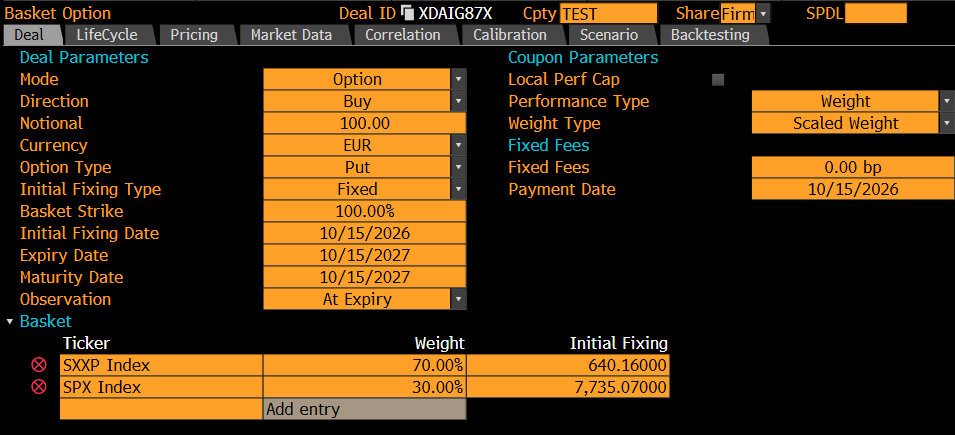

***Calibrating the forwards on the forwards implied by the counterparty single index option prices***
**SXXP Forward:**

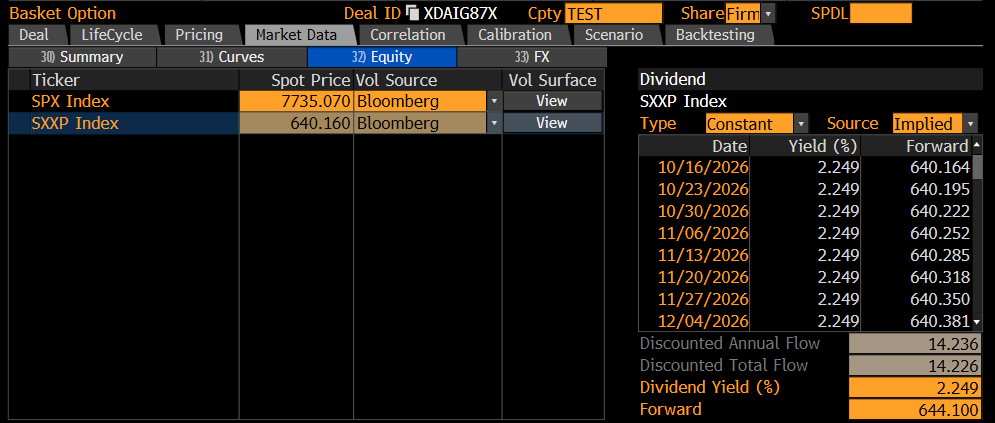

**SPX Forward:**

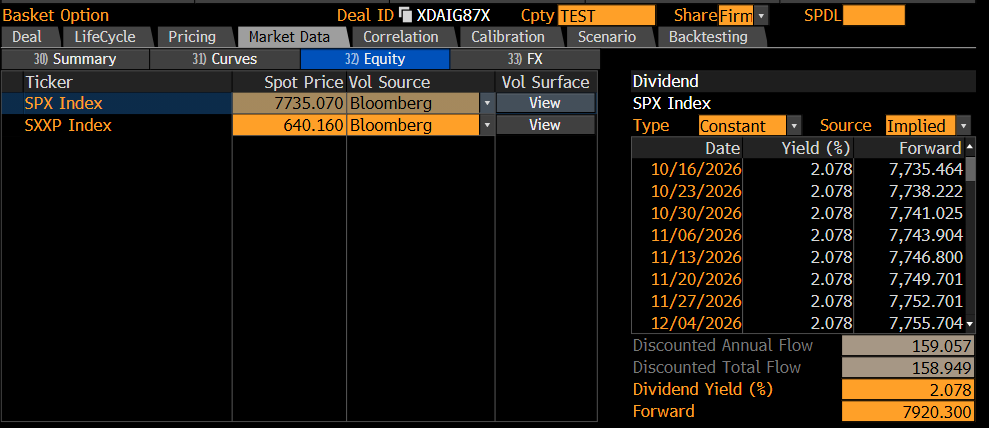

***USDEUR Spot is taken from Bloomberg OVML which we are using as a source for the forward and volatility, the 1Y forward is calculated by DLIB:***

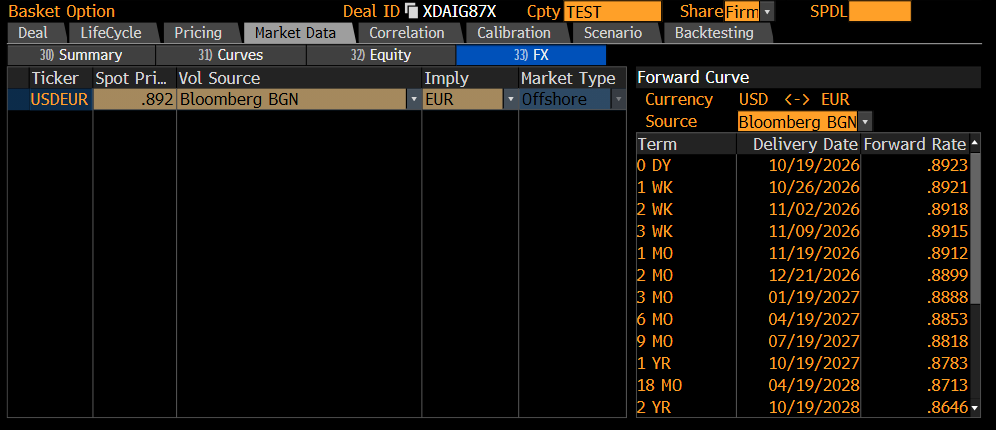

***EUR discount curve:***
Different methodology from us, DLIB uses the EUR S45 curve implied by the USDEUR FX Forward. We are using the EUR curve as the reference curve, so we directly use the S45 curve, not the implied curve (we do not include the basis impiled by the FX forward).

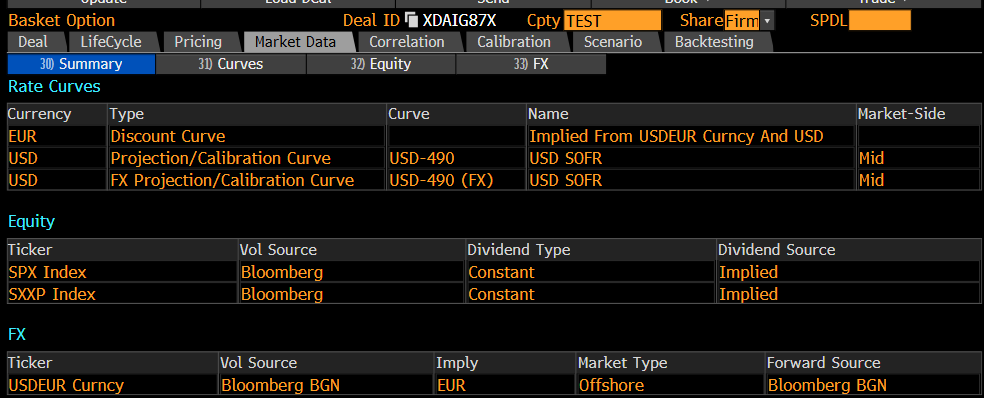

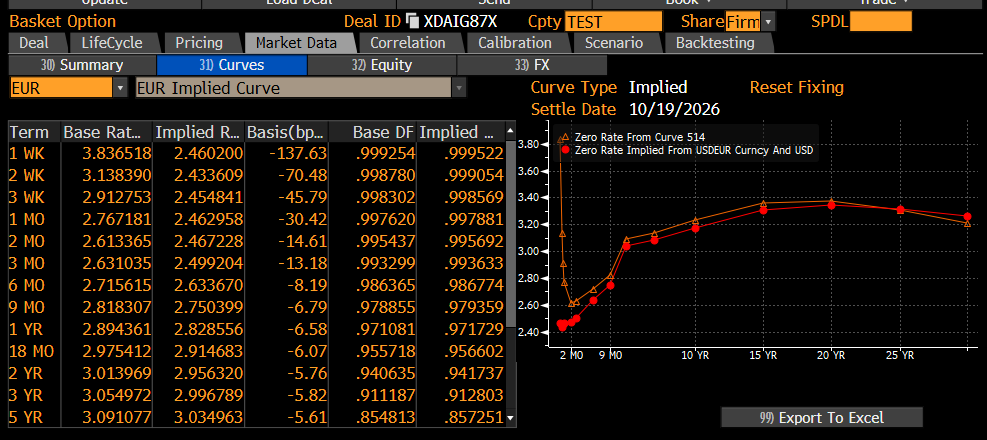

***USD curve:***
USD SOFR curve is used as a reference curve. The same we use in the FX forward screen in OVML. 
DLIB is positioning itself as a USD based investor, i.e. the refererence curve is the USD one, and since we are pricing in EUR it is using the EUR implied curve, being EUR a foreign currency to a USD based investor. 

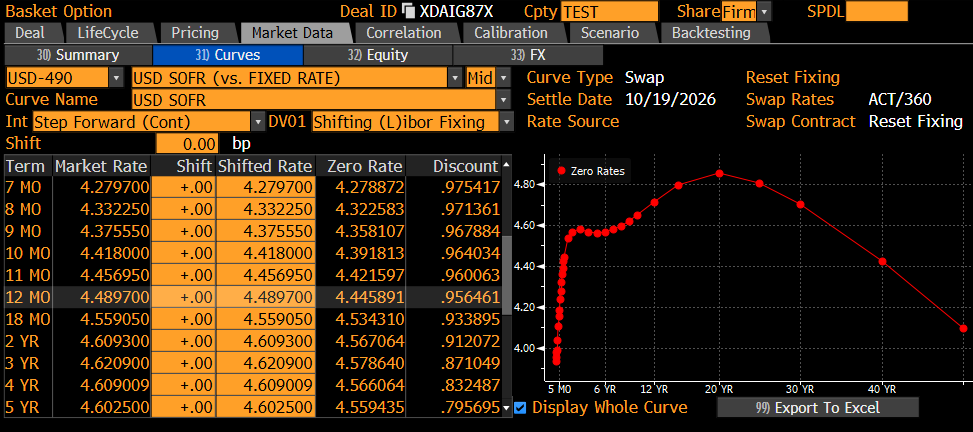

***USD FX curve***

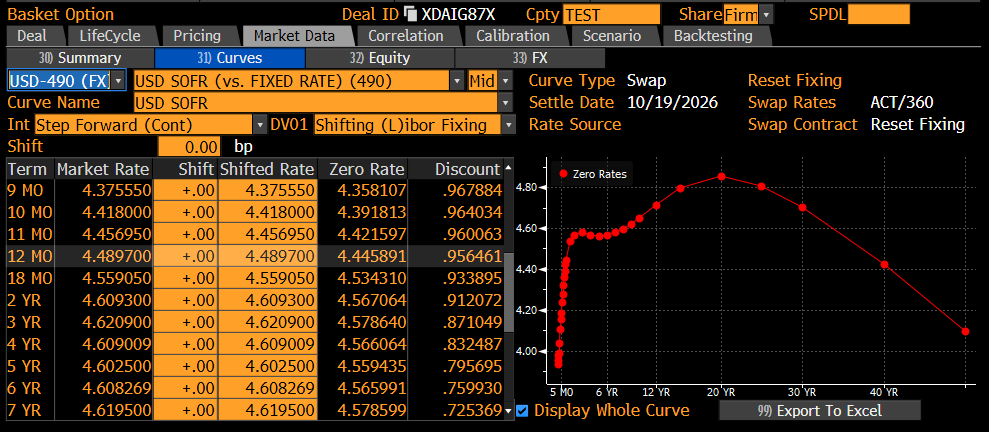

***Correlation matrix:***
We use the implied correlation between SPX and SXXP given by the counterparty. The 10Y weekly frequency estimate for the correlation betweeen the indices and USDEUR. 

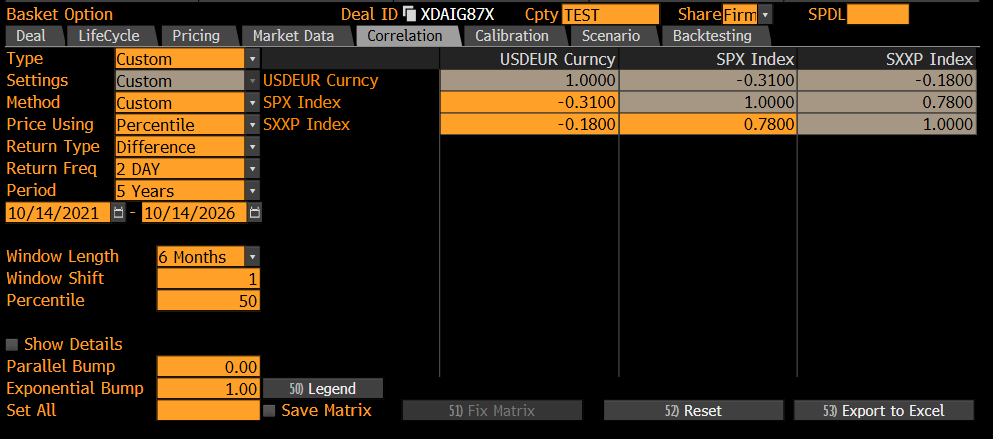

***Vol for USDEUR taken from OVML:***

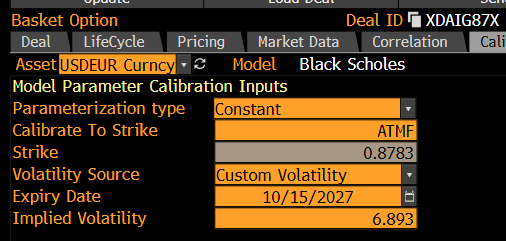

***Indices vol from the counterparty:***

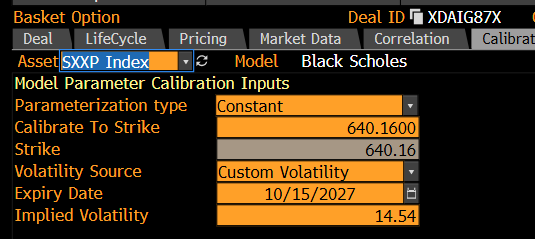

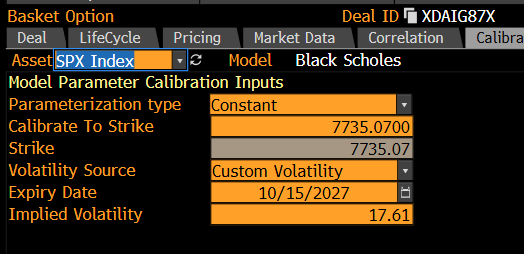


##### <a id='toc4_2_5_1_1_'></a>[Comparison results](#toc0_)
***DLIB Price and MC summmary results***

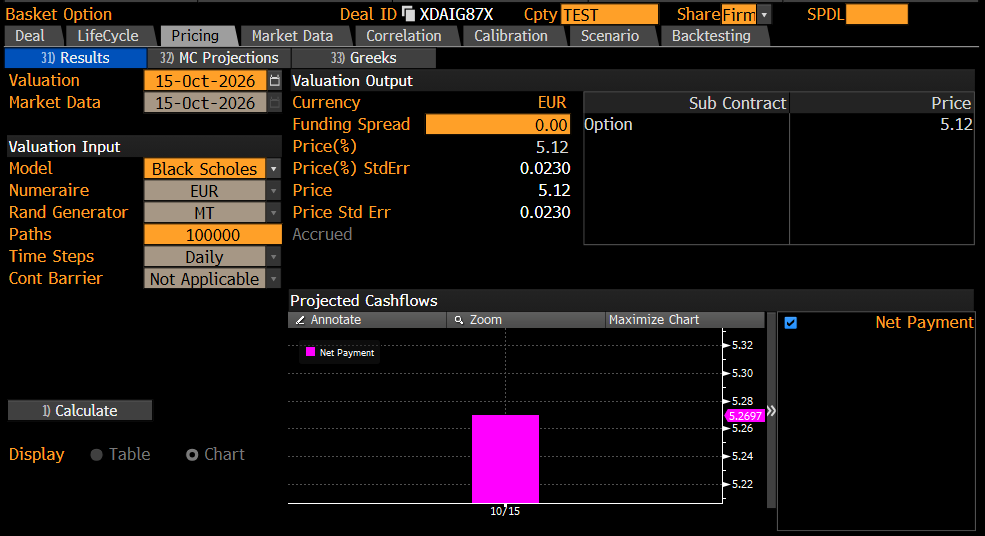

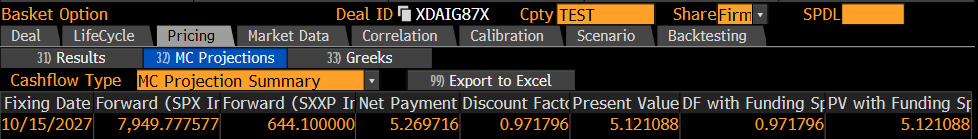


Results:

In [158]:
## Results 
print(f"Simulated forward price: {np.mean(fwd_sim_prices, axis=1).round(2)}")
print(f"\nQuanto basket mean undiscounted payoffs are: {np.round(np.mean(quanto_basket_payoffs*100),4)}")
print(f"Discount factor:{np.round(np.exp(-r_disc * T),4)}")
print(f"\nOption price (%): {np.round(put_quanto_basket_price*100,2)}% vs DLIB price of 5.12%") 
print(f"\nDifference in bps my price vs DLIB: {np.round(((put_quanto_basket_price*100/5.121088)-1)*10000,2)}") 
print(f"\nOption price (%) from the counterparty: {np.round(basket_price_cpty*100,2)}%")


Simulated forward price: [ 644.09 7949.74]

Quanto basket mean undiscounted payoffs are: 5.2744
Discount factor:0.9691

Option price (%): 5.11% vs DLIB price of 5.12%

Difference in bps my price vs DLIB: -19.14

Option price (%) from the counterparty: 5.07%


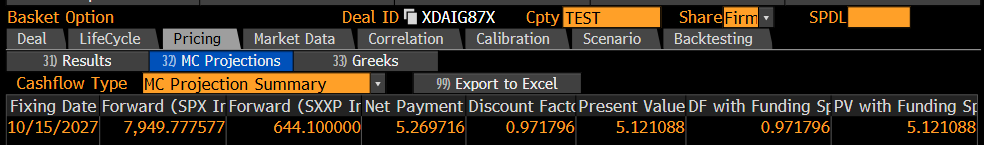

#### <a id='toc4_2_5_2_'></a>[DLIB Comparison inverting the reference curve](#toc0_)
Here we want to perfectly replicate DLIB, so we also change the curves used. We'll use the USD curve as reference and the EUR curve as implied in order to match the drifts and discount rates with the ones seen in DLIB. 

Let's update only the parameters that are changing and reprice. 

Notice: 
**DLIB shows zero rates not in continuous compounding. So we use the continuous rate calculated from OVML, which are equivalent to the zero rates available in the DLIB screens: 

OVML with continuous rates: 

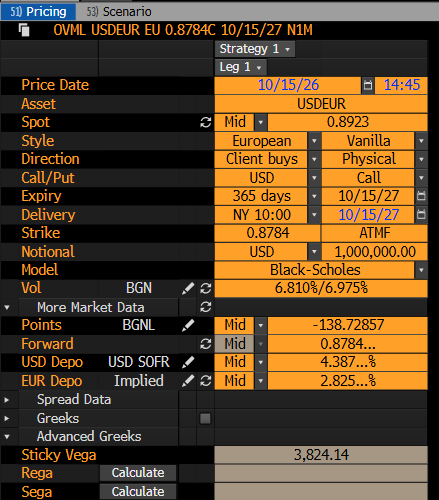

OVML with Zero rates: 

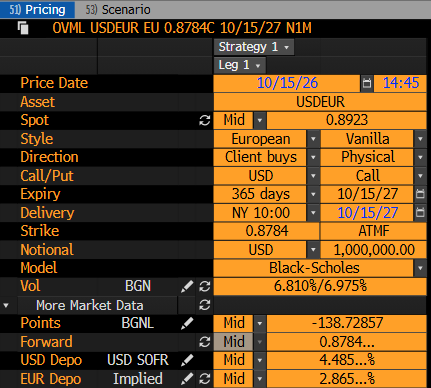

DLIB matching OVML with Zero rates: 

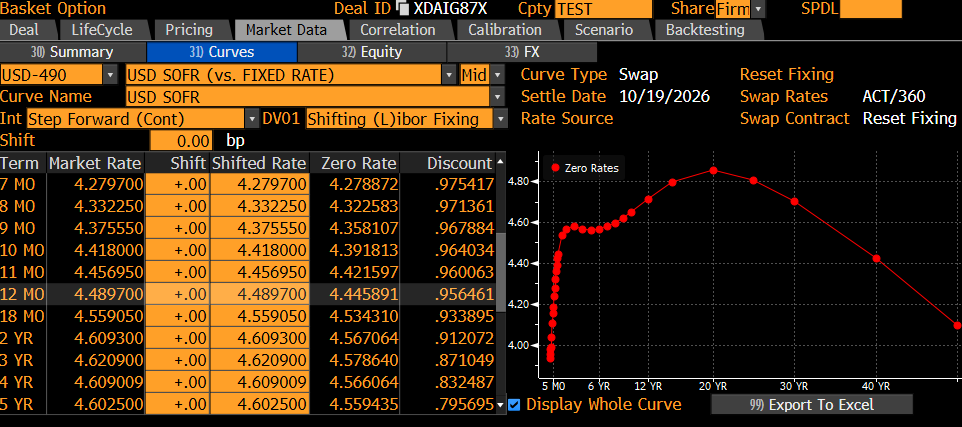

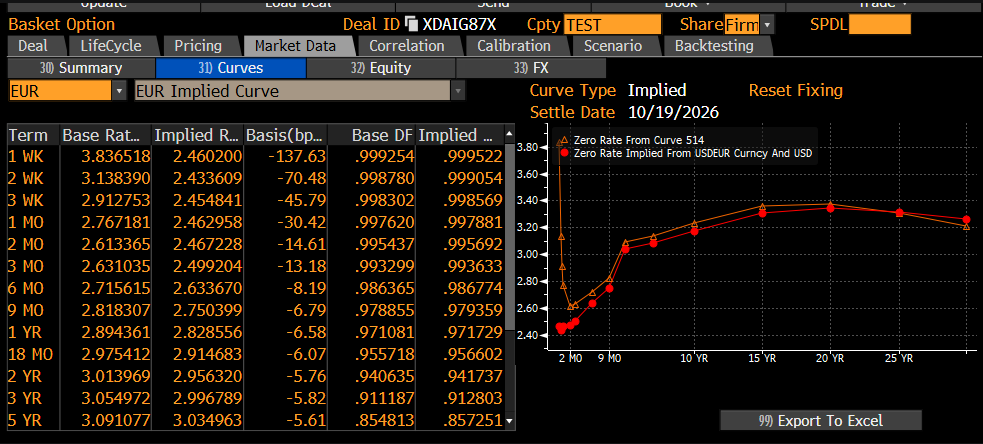

##### <a id='toc4_2_5_2_1_'></a>[Comparison results](#toc0_)

In [159]:
# save previous price
put_quanto_basket_price_EUR_collateral = put_quanto_basket_price

## option parameters assuming USD collateral
r = np.array([0.03142, 0.0438746]).reshape(num_assets,1)  # continuous risk-free rate EUR and USD 
                                                            # (the risk free in the drift in EUR stays without the basis)
                                                            # we calibrated on the forward so doesn't impact
r_disc = 0.0282486 # discounting using the EUR curve with the basis (USD COLLATERAL ASSUMED)
b = r_disc-r[0] # implied basis from FX forward 

# Getting useful quantities
# use q implied by the forward, spot and risk-free rate
q = r - 1/T * np.log(fwd_OVME/S_0) # vector of continuous dividend yields USD 
theoretical_fwd = S_0 * np.exp((r - q) * T) # vector of theoretical forward prices for SXXP and SXP (identical to OVME forward prices by construction)
## ADJUSTED DRIFT TERM FOR CORRELATION BETWEEN USD AND SPX, ALL THE REST IS THE SAME AS THE VANILLA PUT PRICING
mu_quanto = r[1,0] - q[1,0] - corr_spx_usd*vol_idx[1,0]*vol_fx # drift term is adjusted for correlation between USD and SPX
# create the vector of drifts adjusted for the quanto where needed
mu_sxxp = r[0,0]-q[0,0]
mu = np.array([mu_sxxp, mu_quanto]).reshape(num_assets,1)

# Repricing
fwd_sim_prices = simulate_prices_multi(S_0, mu, vol_idx, T, sim_num, num_assets, corr_idx_m, seed)
quanto_basket_payoffs = calc_quanto_basket_payoff(weights, strike, mu, vol_idx, T, sim_num, num_assets, corr_idx_m, style, seed)
put_quanto_basket_price = quanto_basket_option_pricer_MC(weights, strike, mu, r_disc, vol_idx, T, num_assets, corr_idx_m, sim_num, style, seed)

## Results 
print(f"Simulated forward price: {np.mean(fwd_sim_prices, axis=1).round(2)}")
print(f"\nQuanto basket mean undiscounted payoffs are: {np.round(np.mean(quanto_basket_payoffs*100),4)}")
print(f"Discount factor:{np.round(np.exp(-r_disc * T),4)}")
print(f"\nOption price (%): {np.round(put_quanto_basket_price*100,2)}% vs DLIB price of 5.12%")
print(f"\nDifference in bps my price vs DLIB: {np.round(((put_quanto_basket_price*100/5.121088)-1)*10000,2)}")
print(f"\nOption price (%) from the counterparty: {np.round(basket_price_cpty*100,2)}%")

put_quanto_basket_price_USD_collateral = put_quanto_basket_price

Mean undiscounted payoff:0.0527

Discount factor: 0.9721
Simulated forward price: [ 644.09 7949.74]

Quanto basket mean undiscounted payoffs are: 5.2744
Discount factor:0.9721

Option price (%): 5.13% vs DLIB price of 5.12%

Difference in bps my price vs DLIB: 12.57

Option price (%) from the counterparty: 5.07%


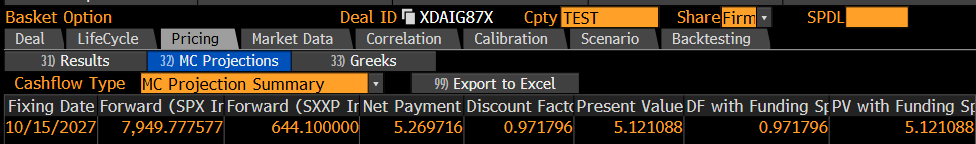

##### <a id='toc4_2_5_2_2_'></a>[Check if price difference is explained by the basis on the discount rate](#toc0_)

In [160]:
print(f"The basis is: {np.round(b, 4)}")
print(f"The impact on the discount factor is explained by a factor exp(-b*T) of {np.exp(b*T)}")
print(f"USD collateralized price is {put_quanto_basket_price_USD_collateral}")
print(f"EUR collateralized price is {put_quanto_basket_price_EUR_collateral}")
print(f"Difference between option prices:{put_quanto_basket_price_USD_collateral - put_quanto_basket_price_EUR_collateral}")
print(f"USD collateralized price is {put_quanto_basket_price_USD_collateral} times exp(b*T) {np.exp(b*T) } is equal to") 
print(f"{put_quanto_basket_price_USD_collateral*np.exp(b*T)}")
print(f"Difference of the USD collateralized price adjusted for the basis vs EUR collateralized price is {put_quanto_basket_price_USD_collateral*np.exp(b*T)-put_quanto_basket_price_EUR_collateral}")

The basis is: [-0.0032]
The impact on the discount factor is explained by a factor exp(-b*T) of [0.99683362]
USD collateralized price is 0.05127522759040026
EUR collateralized price is 0.05111287091867335
Difference between option prices:0.0001623566717269126
USD collateralized price is 0.05127522759040026 times exp(b*T) [0.99683362] is equal to
[0.05111287]
Difference of the USD collateralized price adjusted for the basis vs EUR collateralized price is [0.]


#### <a id='toc4_2_5_3_'></a>[Impact of correlation on the option price](#toc0_)

Mean undiscounted payoff:0.0516

Discount factor: 0.9721
Mean undiscounted payoff:0.0518

Discount factor: 0.9721
Mean undiscounted payoff:0.052

Discount factor: 0.9721
Mean undiscounted payoff:0.0521

Discount factor: 0.9721
Mean undiscounted payoff:0.0523

Discount factor: 0.9721
Mean undiscounted payoff:0.0524

Discount factor: 0.9721
Mean undiscounted payoff:0.0526

Discount factor: 0.9721
Mean undiscounted payoff:0.0528

Discount factor: 0.9721
Mean undiscounted payoff:0.0529

Discount factor: 0.9721
Mean undiscounted payoff:0.0531

Discount factor: 0.9721
Mean undiscounted payoff:0.0532

Discount factor: 0.9721
Mean undiscounted payoff:0.0534

Discount factor: 0.9721
Mean undiscounted payoff:0.0536

Discount factor: 0.9721
Mean undiscounted payoff:0.0537

Discount factor: 0.9721
Mean undiscounted payoff:0.0539

Discount factor: 0.9721
Mean undiscounted payoff:0.0541

Discount factor: 0.9721
Mean undiscounted payoff:0.0542

Discount factor: 0.9721
Mean undiscounted payoff:0.0544


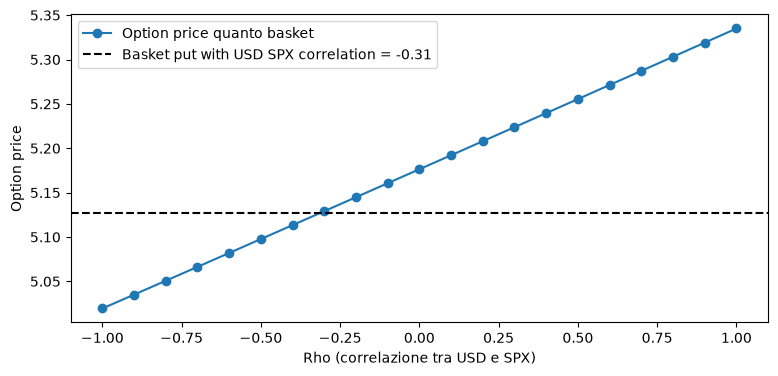

In [161]:
quanto_price_plot = []
step = 0.1
rho_range= np.arange(-1, 1.1, step)
mu_spx_NO_quanto = mu[1] + corr_spx_usd*vol_idx[1]*vol_fx

for rho_i in rho_range:
    mu_spx_i = mu_spx_NO_quanto - rho_i*vol_idx[1]*vol_fx # drift term is adjusted for correlation between USD and SPX
    mu_quanto_i = np.vstack((mu[0], mu_spx_i))
    quanto_price = quanto_basket_option_pricer_MC(weights, strike, mu_quanto_i, r_disc, vol_idx, T, num_assets, corr_idx_m, sim_num, style, seed)
    quanto_price_plot.append(quanto_price*100)

for i in np.arange(0, len(quanto_price_plot),1):
    rho = rho_range[i]
    rho_fx_sensitivity = (quanto_price_plot[i] - quanto_price_plot[i-1])/step
    print(f"Sensitivity to USD-SPX correlation when corr  0 {np.round(rho,2)} is: {np.round(rho_fx_sensitivity, 2)}")

# Visualizziamo la variazione nel fwd al variare della correlazione tra USD e SPX
plt.figure(figsize=(9, 4))
plt.plot(rho_range, quanto_price_plot, marker='o', label='Option price quanto basket')
plt.axhline(put_quanto_basket_price*100, color='black', linestyle='--', label=f"Basket put with USD SPX correlation = {corr_spx_usd}")
plt.xlabel('Rho (correlazione tra USD e SPX)')
plt.ylabel('Option price')
plt.legend()
plt.show()

### <a id='toc4_2_6_'></a>[Pricing the basket calibrating on OVME data](#toc0_)
Let's price the option using the forward observed on OVME to see how large is the difference.

***OVME on SPX only using the counterparty vol***

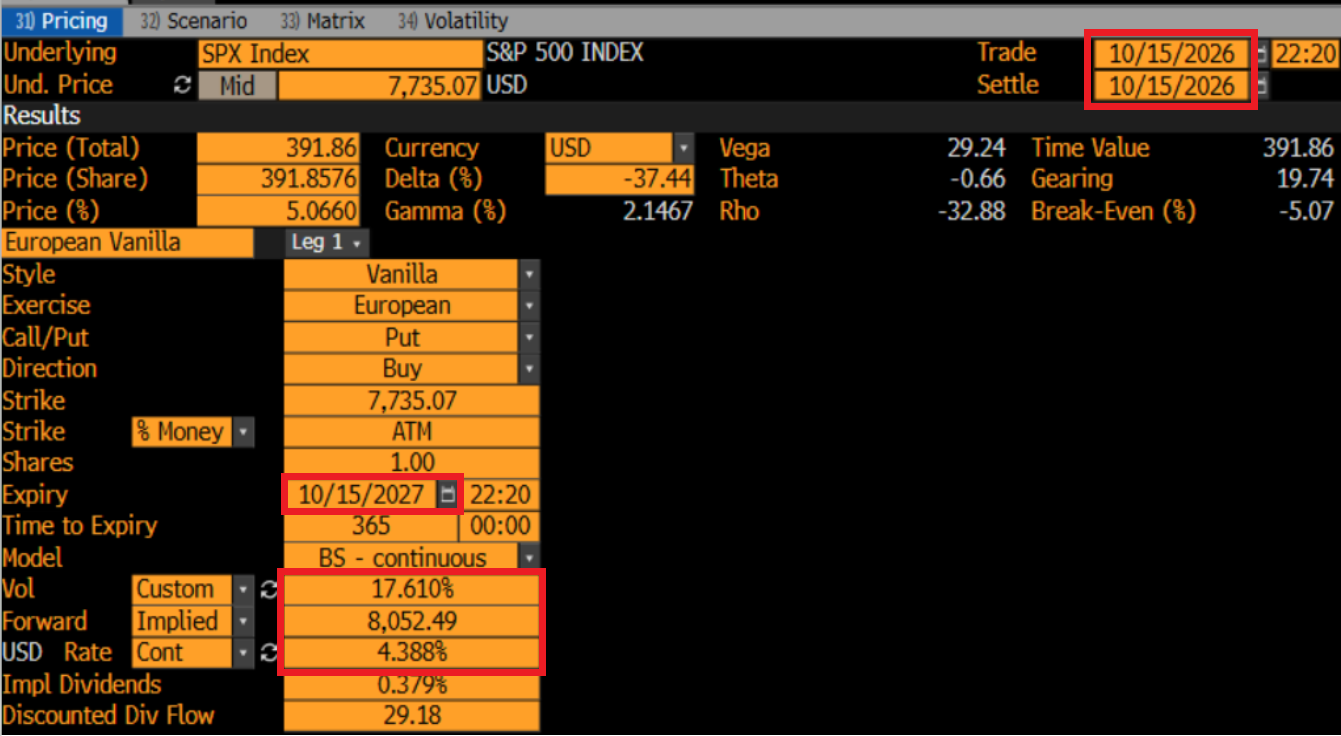

***OVME on SXXP only using the counterparty vol***

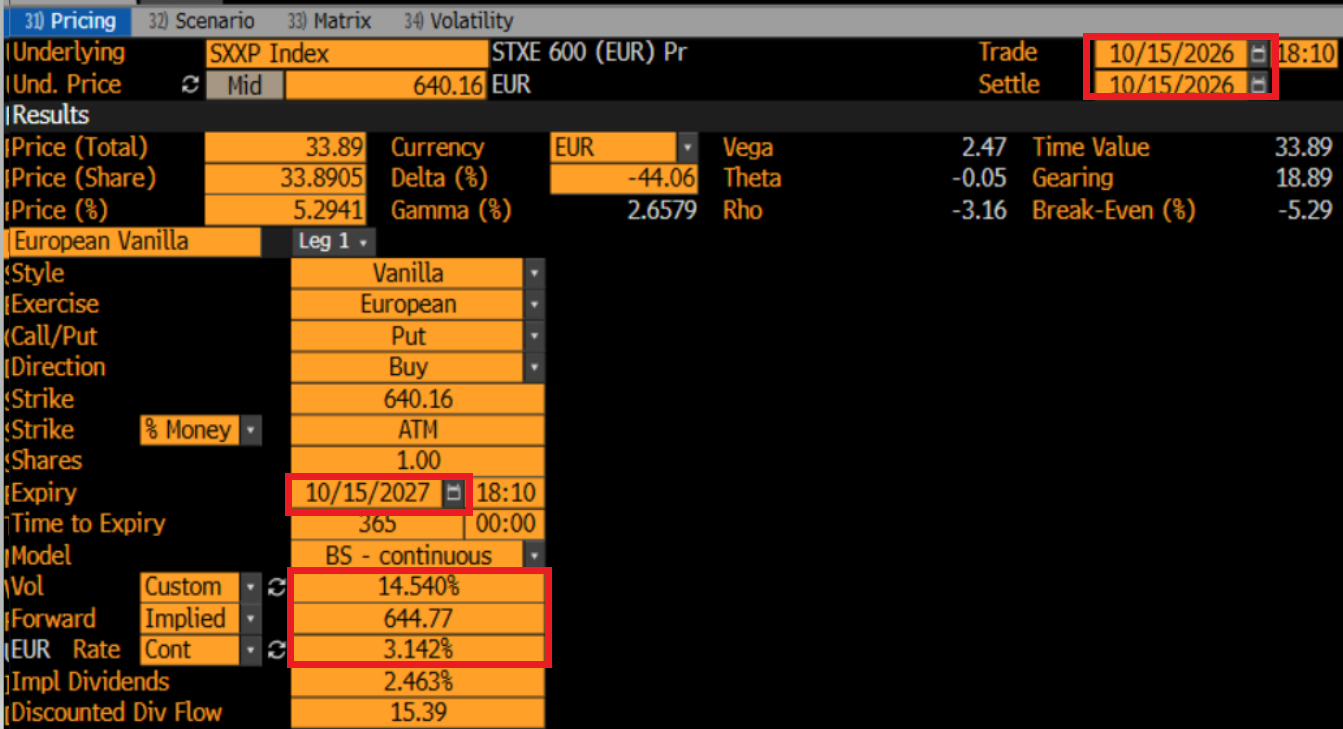

#### <a id='toc4_2_6_1_'></a>[Option parameters](#toc0_)

In [162]:
## option parameters
T = 1 # time to maturity in years
weights = np.array([0.7, 0.3]) # weights for SXXP and SXP 
S_0 = np.array([640.16, 7_735.07])
num_assets = len(S_0)
S_0 = S_0.reshape(num_assets,1) # spot at valuation date for SXXP and SXP
strike = 1 # strike expressed in decimal as multiplier of the basket value at inception
r = np.array([0.03142, 0.04388]).reshape(num_assets,1)  # continuous risk-free rate EUR and USD
r_disc = 0.03142 # discounting using the EUR curve
fwd_OVME = np.array([644.77, 8052.49]).reshape(num_assets,1) 
vol_idx = np.array([0.1454, 0.1761]).reshape(num_assets,1) # annual implied volatility in percentage taken from counterparty quotes
vol_fx = 0.068925 # mid vol from the screenshot
corr_spx_usd = -0.31 # using the 1Y daily historical correlation between USDEUR and SPX
corr_idx = 0.78 # implied correlation between SXXP and SXP, taken from counterparty quotes
style = 'put'
basket_price_cpty = 0.0507

corr_idx_m = np.array([[1, corr_idx], [corr_idx,1]]) # correlation matrix, used for simulating normal correlated random variables



print(f"Correlation matrix for the two indices:\n {corr_idx_m}")
print(f"\nCorrelation between SPX and USD:\n{corr_spx_usd}")
print(f"Risk free rates: {r}")
print(f"FX vol: {vol_fx}")
print(f"Basket option price from counterparty:{basket_price_cpty:.2%}")

Correlation matrix for the two indices:
 [[1.   0.78]
 [0.78 1.  ]]

Correlation between SPX and USD:
-0.31
Risk free rates: [[0.03142]
 [0.04388]]
FX vol: 0.068925
Basket option price from counterparty:5.07%


Getting useful quantities

In [163]:
# use q implied by the forward, spot and risk-free rate
q = r - 1/T * np.log(fwd_OVME/S_0) # vector of continuous dividend yields USD 
theoretical_fwd = S_0 * np.exp((r - q) * T) # vector of theoretical forward prices for SXXP and SXP (identical to OVME forward prices by construction)
## ADJUSTED DRIFT TERM FOR CORRELATION BETWEEN USD AND SPX, ALL THE REST IS THE SAME AS THE VANILLA PUT PRICING
mu_quanto = r[1,0] - q[1,0] - corr_spx_usd*vol_idx[1,0]*vol_fx # drift term is adjusted for correlation between USD and SPX
# create the vector of drifts adjusted for the quanto where needed
mu_sxxp = r[0,0]-q[0,0]
mu = np.array([mu_sxxp, mu_quanto]).reshape(num_assets,1)
theoretical_fwd_quanto = S_0 * np.exp((mu) * T)

print("Printing various quantities for the SXXP and SXP indices:")
print(f"\nSpot price: {np.round(S_0, 2)}")
print(f"Strike price: {strike*100:.2f}% of the basket value at inception")
print(f"Risk-free rate: \n{np.array2string(r, formatter={"float_kind": lambda x: f"{x:.5f}"})}")
print(f"Dividend yield: \n{np.array2string(q, formatter={"float_kind": lambda x: f"{x:.5f}"})}")
print(f"Discount rate: \n{r_disc}")

print(f"Drifts in % with the USD drift quanto adjusted =\n {np.round(mu*100,4)}")

print("\nMaking sure the theoretical forward price is consistent with the OVME forward price:")
print(f"\nForward price OVME:\n {np.round(fwd_OVME,2)}")
print(f"\nForward price recalculated S0*exp((r-q)*T) without the quanto adjustment:\n {np.round(theoretical_fwd,2)}")
print(f"\nForward price using the quanto adj on the SPX :\n {np.round(theoretical_fwd_quanto,2)}")


Printing various quantities for the SXXP and SXP indices:

Spot price: [[ 640.16]
 [7735.07]]
Strike price: 100.00% of the basket value at inception
Risk-free rate: 
[[0.03142]
 [0.04388]]
Dividend yield: 
[[0.02424]
 [0.00366]]
Discount rate: 
0.03142
Drifts in % with the USD drift quanto adjusted =
 [[0.7176]
 [4.398 ]]

Making sure the theoretical forward price is consistent with the OVME forward price:

Forward price OVME:
 [[ 644.77]
 [8052.49]]

Forward price recalculated S0*exp((r-q)*T) without the quanto adjustment:
 [[ 644.77]
 [8052.49]]

Forward price using the quanto adj on the SPX :
 [[ 644.77]
 [8082.85]]


#### <a id='toc4_2_6_2_'></a>[Getting quanto basket option prices](#toc0_)

In [164]:
put_quanto_basket_price_new = quanto_basket_option_pricer_MC(weights, strike, mu, r_disc, vol_idx, T, num_assets, corr_idx_m, sim_num, style, seed)

print(f"\nOption price (%) from the counterparty: {np.round(basket_price_cpty*100,2)}%")
print(f"\nOption price (%) using implied forward from conuterparty: {np.round(put_quanto_basket_price*100,2)}%")
print(f"Difference vs counterparty price: {np.round((put_quanto_basket_price/basket_price_cpty-1)*10000,2)} bps")
print(f"\nOption price (%) using forward from Bloomberg OVME but vols from counterparty: {np.round(put_quanto_basket_price_new*100,2)}%")
print(f"Difference vs counterparty price: {np.round((put_quanto_basket_price_new/basket_price_cpty-1)*10000,2)} bps")


Mean undiscounted payoff:0.0502

Discount factor: 0.9691

Option price (%) from the counterparty: 5.07%

Option price (%) using implied forward from conuterparty: 5.13%
Difference vs counterparty price: 113.46 bps

Option price (%) using forward from Bloomberg OVME but vols from counterparty: 4.87%
Difference vs counterparty price: -396.5 bps


## <a id='toc4_3_'></a>[Basket composite pricing](#toc0_)
This option will be on a basket where the performance of the basket is also impacted by the USDEUR exchange rate at expiry. 

Steps: 
1. We'll now simulate separately the 3 assets: 
    - SPX
    - SXXP
    - USDEUR
2. Caculate the basket value at expiry and relative discounted payoff

We are simulating the 3 assets under the EUR measure (we are discounting in EUR). So far for the quanto option we simulated the SPX under the EUR measure and with constant fx rate. Now we have to simulate the SPX and imclude the impact from the FX. 

We have two options to do that:

1. Simulate Y = SPX * X directly i.e the SPX converted in EUR at each point in time. Where SPX is the index level in USD and X is USDEUR. 
2. Simulate the SPX and X separately taking into account their correlation.

### <a id='toc4_3_1_'></a>[Nuances in the methodology](#toc0_)
To be consistent with the EUR measure and with the fact that we are under the EUR measure we'll have again to simulate the SPX using the quanto adjustment. 

Why? 

Under the EUR measure the SPX has drift $\mu_{USD} - \rho\sigma_{SPX}\sigma{X}$ see below to see why. An asset in EUR (i.e. the SPX converted in EUR) must under risk free EUR measure must have drift = $r_{EUR}-q$. From that condition the drift under the EUR measure for the SPX is derived. 

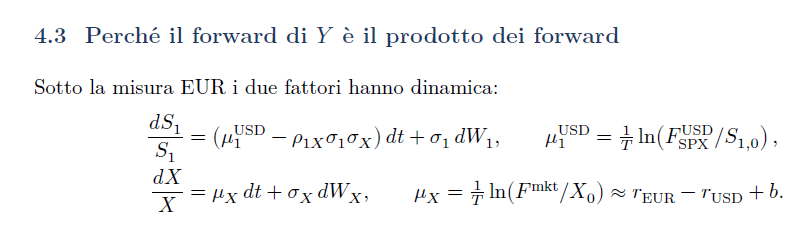

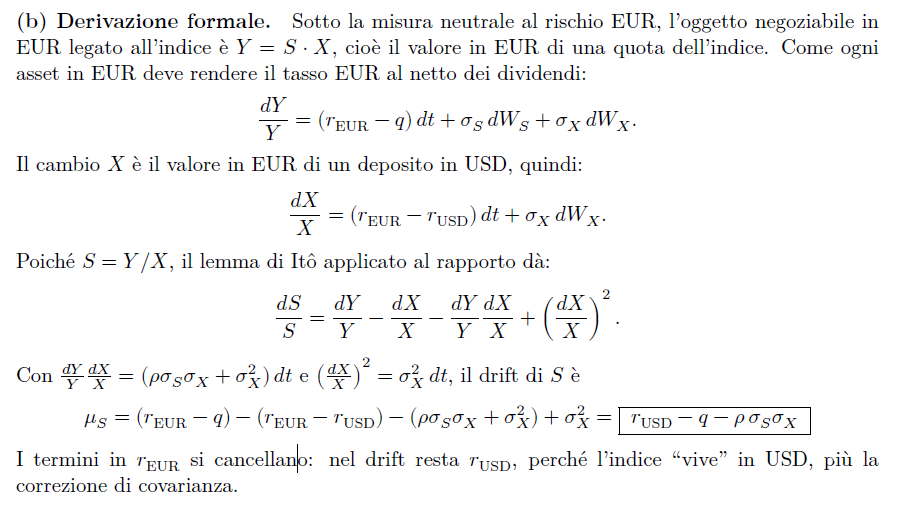

### <a id='toc4_3_2_'></a>[Pricing using 3 factors](#toc0_)

#### <a id='toc4_3_2_1_'></a>[Calibration inputs](#toc0_)
We assume to be pricing a 1 year ATM put option on a basket composed of the SPX Index and SXXP Index as of 15-oct-2026 where the SPX component is quanto adjusted.

The weights are: 
- $w_1 = w_{sxxp} $
- $w_2 = w_{spx} $ 

and the value at expiry of the basket is calculated as follows: 
$$Basket_T= \frac{S^1_T X_T}{S^1_t X_t}  * w_1 + S^2_T/S^2_t * w_2$$

Notice: 
- there is no weight rebalancing on the basket;
- there IS impact from the currency the basket performance.

Where possible we'll use inputs given from a counterparty in order to match their price on the basket option and price in consistency with the pricing of the single index options priced ealier: 

The inputs will be the same as the ones used for the quanto basket see the relative section for the sources. 

- From the counterparty we use:
    - Implied vol of the indices
    - Implied correlation between indices
    - Single index put option prices to infer the forward price

- From OVME we get:
    - risk free in EUR and USD
    - forward index level implied by the counterparty option price and vols on single index options
    - risk free in EUR
    - forward index level implied by the counterparty option price and vols on single index options

- and USD including the basis is taken from Bloomberg OVML USDEUR 1Y ATMF option

    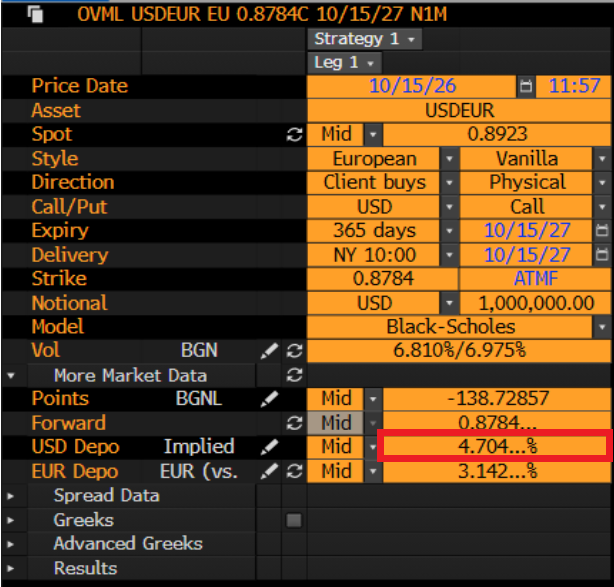

- Exchange rate vol is taken from Bloomberg OVML USDEUR 1Y ATMF option (not provided by the counterparty; we use the ATM FORWARD implied vol since it centered in the forward distribution, notice that it doesn't impact directly the return of the basket in the quanto option, it enters only via the quanto drift adjustment);

- For the correlation between SPX and USDEUR we use an historical estimate done in the following section. Estimate has been done on different lookbacks and the 1Y daily estimate has been used for pricing.

##### <a id='toc4_3_2_1_1_'></a>[Estimating correlation matrix using data until the previous valuation day Oct 14th 26:](#toc0_)

In [165]:
import pandas as pd
from xbbg import blp

In [166]:
# tickers to download
tickers = ['SXXP Index', 'SPX Index', 'EUUS F160 Curncy']

# Lookback data
start_date = pd.to_datetime('20161014')
end_date = pd.to_datetime('20261014')
currency = None
field = "PX_LAST"

Dowload and clean the data via Bloomberg python blp.bdh

In [167]:
# download raw data
try: 
    raw_df = blp.bdh(tickers, field, start_date, end_date, currency = currency).to_native()
    time_series = pd.DataFrame(columns=['date'])
except:
    print("currency= None, using bdh formula without currency")
    raw_df = blp.bdh(tickers, field, start_date, end_date).to_native()
    time_series = pd.DataFrame(columns=['date'])

currency= None, using bdh formula without currency


In [168]:
# tidy up and clean the data
for ticker in tickers:
    filtered_df = raw_df[raw_df['ticker'] == ticker].drop(columns=['ticker', 'field'])
    filtered_df = filtered_df.rename(columns={'value': ticker}).copy()

    time_series = pd.merge(time_series, filtered_df, how = 'outer', on = 'date')

time_series.index = pd.to_datetime(time_series['date'])
time_series.drop(columns = 'date', inplace = True)

# remove dates if any assets are in holiday for a given date (avoid using stale observations to calculate log returns)
time_series.dropna(how='any', inplace = True)
time_series.to_csv('3fact_corr.csv')

# sort dates descending
time_series.sort_index(axis=0, ascending=False, inplace=True)

print("Some info on the dataframe:")
print('\n')
print('Head')
print(time_series.head())
print('Tail')
print(time_series.tail())
print('\n')
print('Describe')
print(time_series.describe())
print('\n')
print('Info')
print(time_series.info())


Some info on the dataframe:


Head
            SXXP Index  SPX Index  EUUS F160 Curncy
date                                               
2026-10-14      637.75    7718.94            0.8964
2026-10-13      635.01    7805.45            0.8930
2026-10-12      635.65    7807.24            0.8965
2026-10-09      631.55    7811.54            0.8929
2026-10-08      625.51    7765.36            0.8918
Tail
            SXXP Index  SPX Index  EUUS F160 Curncy
date                                               
2016-10-20      344.29    2141.34            0.9152
2016-10-19      343.64    2144.29            0.9116
2016-10-18      342.48    2139.60            0.9107
2016-10-17      337.42    2126.50            0.9088
2016-10-14      339.95    2132.98            0.9114


Describe
        SXXP Index    SPX Index  EUUS F160 Curncy
count  2497.000000  2497.000000       2497.000000
mean    447.271077  4179.013292          0.891507
std      80.512961  1499.293614          0.043970
min     279.660000  2

Get weekly data

In [169]:
# resample weekly prices on a Friday or last available price
time_series_weekly = time_series.resample("W-FRI").last().sort_index(ascending=False)
# drop first or last observation if first and last dates are not on Friday to avoid using a shorter period of time
if time_series.index[0].day_name() != 'Friday': 
    time_series_weekly = time_series_weekly.iloc[1:]
elif time_series.index[-1].day_name():
    time_series_weekly = time_series_weekly.iloc[:-1]

print("Some info on the weekly prices:")
print('\n')
print('Head')
print(time_series_weekly.head())
print('Tail')
print(time_series_weekly.tail())
print('\n')
print('Describe')
print(time_series_weekly.describe())
print('\n')
print('Info')
print(time_series_weekly.info())


Some info on the weekly prices:


Head
            SXXP Index  SPX Index  EUUS F160 Curncy
date                                               
2026-10-09      631.55    7811.54            0.8929
2026-10-02      631.35    7722.72            0.8884
2026-09-25      638.65    7743.41            0.8775
2026-09-18      635.45    7650.50            0.8706
2026-09-11      639.10    7656.98            0.8624
Tail
            SXXP Index  SPX Index  EUUS F160 Curncy
date                                               
2016-11-11      337.50    2164.45            0.9219
2016-11-04      328.80    2085.18            0.8979
2016-10-28      340.80    2126.41            0.9104
2016-10-21      344.29    2141.16            0.9191
2016-10-14      339.95    2132.98            0.9114


Describe
       SXXP Index    SPX Index  EUUS F160 Curncy
count  522.000000   522.000000        522.000000
mean   447.123736  4176.464559          0.891605
std     80.563911  1498.436132          0.043993
min    293.040000  20

Get log returns and estimate correlation. 

Daily:

In [170]:
# get log returns for each asset
log_ret_d = np.log(time_series / time_series.shift(-1))
# remove first obs NA
log_ret_d.dropna(inplace=True)

print("Some info on the Daily log ret:")
print('\n')
print('Describe')
print(log_ret_d.describe())
print('\n')
print('Info')
print(log_ret_d.info())
print('\n')
print('Head')
print(log_ret_d.head())
print('Tail')
print(log_ret_d.tail())

Some info on the Daily log ret:


Describe
        SXXP Index    SPX Index  EUUS F160 Curncy
count  2496.000000  2496.000000       2496.000000
mean      0.000252     0.000515         -0.000007
std       0.009545     0.011423          0.004530
min      -0.121915    -0.127652         -0.022908
25%      -0.003955    -0.003772         -0.002773
50%       0.000635     0.000804          0.000000
75%       0.005220     0.005876          0.002722
max       0.080704     0.090895          0.020388


Info
<class 'pandas.DataFrame'>
DatetimeIndex: 2496 entries, 2026-10-14 to 2016-10-17
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SXXP Index        2496 non-null   float64
 1   SPX Index         2496 non-null   float64
 2   EUUS F160 Curncy  2496 non-null   float64
dtypes: float64(3)
memory usage: 78.0 KB
None


Head
            SXXP Index  SPX Index  EUUS F160 Curncy
date                                           

Weekly:

In [171]:
# get log returns for each asset
log_ret_w = np.log(time_series_weekly / time_series_weekly.shift(-1))
# remove first obs NA
log_ret_w.dropna(inplace=True)

print("Some info on the Daily log ret:")
print('\n')
print('Describe')
print(log_ret_w.describe())
print('\n')
print('Info')
print(log_ret_w.info())
print('\n')
print('Head')
print(log_ret_w.head())
print('Tail')
print(log_ret_w.tail())

Some info on the Daily log ret:


Describe
       SXXP Index   SPX Index  EUUS F160 Curncy
count  521.000000  521.000000        521.000000
mean     0.001189    0.002492         -0.000039
std      0.021738    0.023881          0.009843
min     -0.203838   -0.162279         -0.044551
25%     -0.007603   -0.008955         -0.005618
50%      0.002906    0.003946          0.000199
75%      0.012315    0.015039          0.006140
max      0.070997    0.114237          0.039494


Info
<class 'pandas.DataFrame'>
DatetimeIndex: 521 entries, 2026-10-09 to 2016-10-21
Freq: -1W-FRI
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SXXP Index        521 non-null    float64
 1   SPX Index         521 non-null    float64
 2   EUUS F160 Curncy  521 non-null    float64
dtypes: float64(3)
memory usage: 16.3 KB
None


Head
            SXXP Index  SPX Index  EUUS F160 Curncy
date                                               


In [172]:
# estimate correlations
# Daily freq
print("Correlation estimates on DAILY frequency data:")
last_date = log_ret_d.index.max()
for lookback in [1,2,5,10]: 
    lookback_start = last_date - pd.DateOffset(years=lookback)
    print(f"{lookback}Y lookback: {np.round(log_ret_d.loc[log_ret_d.index >= lookback_start].corr(),2)}\n")

# weekly freq
print("\nCorrelation estimates on WEEKLY frequency data:")
last_date = log_ret_w.index.max()
for lookback in [1,2,5,10]: 
    lookback_start = last_date - pd.DateOffset(years=lookback)
    print(f"{lookback}Y lookback: {np.round(log_ret_w.loc[log_ret_w.index >= lookback_start].corr(),2)}\n")


Correlation estimates on DAILY frequency data:
1Y lookback:                   SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.54             -0.20
SPX Index               0.54       1.00             -0.33
EUUS F160 Curncy       -0.20      -0.33              1.00

2Y lookback:                   SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.34             -0.08
SPX Index               0.34       1.00             -0.04
EUUS F160 Curncy       -0.08      -0.04              1.00

5Y lookback:                   SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.46             -0.21
SPX Index               0.46       1.00             -0.26
EUUS F160 Curncy       -0.21      -0.26              1.00

10Y lookback:                   SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.56             -0.08
SPX Index               0.56       1.00             -0.14
EUUS F160 Curncy       -0.0

In [173]:

# correlation chosen - WEEKLY on 10Y lookback
preferred_lookback = 10
last_date = log_ret_d.index.max()
lookback_start_chosen = last_date - pd.DateOffset(years=10)

corr_m = np.round(log_ret_w.loc[log_ret_w.index >= (last_date - pd.DateOffset(years=10))].corr(),2)
print(f"Estimated correlation matrix to be used:")            
print(corr_m)



Estimated correlation matrix to be used:
                  SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.73             -0.18
SPX Index               0.73       1.00             -0.31
EUUS F160 Curncy       -0.18      -0.31              1.00


### <a id='toc4_3_3_'></a>[Option parameters](#toc0_)

In [ ]:
## option parameters
T = 1 # time to maturity in years
weights = np.array([0.7, 0.3, 0]) # weights for SXXP and SXP 
S_0 = np.array([640.16, 7_735.07, 0.8923])
num_assets = len(S_0)
S_0 = S_0.reshape(num_assets,1) # spot at valuation date for SXXP and SXP
strike = 1 # strike expressed in decimal as multiplier of the basket value at inception
r_USD_not_implied = 0.04388
fwd_OVME = np.array([644.10, 7_920.30, 0.8784]).reshape(num_assets,1) 
drift_fx = float(1/T * np.log(fwd_OVME[2,0]/S_0[2,0]))
r = np.array([0.03142, r_USD_not_implied, drift_fx]).reshape(num_assets,1)  # continuous risk-free rate EUR and USD (implied USD)
r_disc = 0.03142 # discounting using the EUR curve
vol = np.array([0.1454, 0.1761, 0.068925]).reshape(num_assets,1) # annual implied volatility in percentage taken from counterparty quotes or OVML
style = 'put'
corr_idx = 0.78 # implied correlation between SXXP and SXP, taken from counterparty quotes
corr_spx_usd = corr_m.loc['SPX Index','EUUS F160 Curncy'] # using the 1Y daily historical correlation between USDEUR and SPX
basket_price_cpty = 0.0507

# imposing the implied correlation from the counterparty on the historically estimated correlation matrix
corr_m.loc['SPX Index','SXXP Index'] = corr_idx
corr_m.loc['SXXP Index','SPX Index'] = corr_idx

# quanto adjustment for the SPX simulated in USD under EUR measure
quanto_adj = np.zeros_like(vol)
quanto_adj[1, 0] = -corr_spx_usd * vol[1, 0] * vol[2, 0]

# calculating the basis on the USD implied rate
b = 0.04704 - r_USD_not_implied

print(f"Correlation matrix for the two indices:\n {corr_m}")
print("\nCheck correlation matrix positive semidefinite after plugging the implied correlation from the cpty:")
print(f"True if passed: {np.linalg.eigvalsh(corr_m.to_numpy()).min() >= -1e-10}")

print(f"\nRisk free rates where on the USD is the implied r: \n{r}")
print(f"\nRisk free rates on USD not implied  is: \n{r_USD_not_implied}")
print(f"\nFX drift:{drift_fx:.4f} while r_EUR-r_USD = {r[0]-r[1]}")
print(f"\nBasis on USD risk free rate is: \n{b}")
print(f"\nFX vol: {vol_fx}")
print(f"\nBasket option price from counterparty:{basket_price_cpty}")

Correlation matrix for the two indices:
                   SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.78             -0.18
SPX Index               0.78       1.00             -0.31
EUUS F160 Curncy       -0.18      -0.31              1.00

Check correlation matrix positive semidefinite after plugging the implied correlation from the cpty:
True if passed: True

Risk free rates where on the USD is the implied r: 
[[ 0.03142   ]
 [ 0.04704   ]
 [-0.01570033]]

Risk free rates on USD not implied  is: 
0.04388

FX drift:-0.0157 while r_EUR-r_USD = [-0.01562]

Basis on USD risk free rate is: 
[0.00316]

FX vol: 0.068925

Basket option price from counterparty:0.0507


Getting useful quantities: 

In [176]:
# use q implied by the forward, spot and risk-free rate
q = r - 1/T * np.log(fwd_OVME/S_0) # vector of continuous dividend yields USD 
mu = r - q # drift term

# add quanto adjustment 
mu = mu + quanto_adj

# create the vector of drifts adjusted for the quanto where needed
theoretical_fwd = S_0 * np.exp((mu) * T) # using implied USD rate

print("Printing various quantities for the SXXP and SXP indices:")
print(f"\nSpot price: {np.round(S_0, 2)}")
print(f"\nStrike price: {strike*100:.2f}% of the basket value at inception")
print(f"\nRisk-free rate: \n{np.array2string(r, formatter={"float_kind": lambda x: f"{x:.5f}"})}")
print(f"\nDividend yield: \n{np.array2string(q, formatter={"float_kind": lambda x: f"{x:.5f}"})}")
print(f"\nDiscount rate: \n{r_disc}")

print(f"\nDrifts in % =\n {np.round(mu*100,4)}")

print("\nMaking sure the theoretical forward price is consistent with the OVME forward price:")
with np.printoptions(suppress=True, precision=4):
    print(f"\nForward price OVME:\n {fwd_OVME}")
    print(f"\nForward price recalculated S0*exp((r-q)*T) without the quanto adjustment:\n {theoretical_fwd}")


Printing various quantities for the SXXP and SXP indices:

Spot price: [[6.40160e+02]
 [7.73507e+03]
 [8.90000e-01]]

Strike price: 100.00% of the basket value at inception

Risk-free rate: 
[[0.03142]
 [0.04704]
 [-0.01570]]

Dividend yield: 
[[0.02528]
 [0.02338]
 [0.00000]]

Discount rate: 
0.03142

Drifts in % =
 [[ 0.6136]
 [ 2.7427]
 [-1.57  ]]

Making sure the theoretical forward price is consistent with the OVME forward price:

Forward price OVME:
 [[ 644.1   ]
 [7920.3   ]
 [   0.8784]]

Forward price recalculated S0*exp((r-q)*T) without the quanto adjustment:
 [[ 644.1   ]
 [7950.1577]
 [   0.8784]]


### <a id='toc4_3_4_'></a>[Simulation inputs](#toc0_)

In [177]:
# simulation inputs
sim_num = 1_000_000 # number of simulations
seed = 100

### <a id='toc4_3_5_'></a>[Simulating the underlying dynamics under EUR measure](#toc0_)

In [178]:
print("\nGENERATING THE SAMPLE OF PRICES AT EXPIRY FROM THE PREVIOSLY GENERATED NORMALS")

def simulate_prices_multi(spot_price, mu, vol, T, sim_num, num_assets, corr_matrix, seed=None):
    _W = sim_multiv_correl_std_norm(sim_num, num_assets, corr_matrix, seed)
    _fwd_sim_prices = spot_price * np.exp(  (mu - 1/2 * vol** 2) * T + vol * np.sqrt(T) * _W ) # forward prices at expiry
    return _fwd_sim_prices

fwd_sim_prices = simulate_prices_multi(S_0, mu, vol, T, sim_num, num_assets, corr_m, seed)

print("\nCheck forward prices:")
print(f"Shape of forward prices: {fwd_sim_prices.shape}")
with np.printoptions(suppress=True, precision=4):
    print(f"\nFirst 5 simultated prices: {fwd_sim_prices[:, :5]}")

    print(f"\nTheoretical forward price: {theoretical_fwd.T}")
    print(f"Mean of simulated forward price: {np.mean(fwd_sim_prices, axis=1)}")


GENERATING THE SAMPLE OF PRICES AT EXPIRY FROM THE PREVIOSLY GENERATED NORMALS

Check forward prices:
Shape of forward prices: (3, 2000000)

First 5 simultated prices: [[  771.8156   673.6908   594.0925   591.7194   692.9652]
 [11255.1709  8627.3801  7257.3875  7605.582   9153.4186]
 [    0.8467     0.9233     0.8276     0.8616     0.9046]]

Theoretical forward price: [[ 644.1    7950.1577    0.8784]]
Mean of simulated forward price: [ 644.0882 7950.051     0.8784]


### <a id='toc4_3_6_'></a>[Getting 3 factors option prices](#toc0_)

In [179]:
# calculate the forward value of the basket on each simulation
def calc_fwd_basket(weights, mu, vol, T, sim_num, num_assets, corr_matrix, seed=None):
    _sim_lnret = simulate_ln_returns_multi(mu, vol, T, sim_num, num_assets, corr_matrix, seed)
    _currcy_lnret = _sim_lnret[2,:] # extract currency log returns
    _currcy_lnret = _currcy_lnret.reshape(1,sim_num*2)
    _currcy_lnret = np.vstack((np.zeros((1,sim_num*2)), _currcy_lnret)) # currency returns on two rows to be multiplied item by item
    _ind_lnret = _sim_lnret[:2,:] # extract index log returns
    # apply exchange rate on second index
    _sim_lnret = (1+_ind_lnret)*(1+_currcy_lnret)-1
    _sim_fwd_basket_prices = np.matmul(weights[:2], 1+_sim_lnret).reshape(1, sim_num*2) # currency weight must be zero
    return _sim_fwd_basket_prices

sim_fwd_basket_prices = calc_fwd_basket(weights, mu, vol, T, sim_num, num_assets, corr_m, seed)

print("\nCheck basket forward prices")
print(f"Shape of forward prices: {sim_fwd_basket_prices.shape}")
print(f"First 5 simultated prices: {np.round(sim_fwd_basket_prices[:, :5], 2)}")
print(f"Simulated basket forward price: {np.round(np.mean(sim_fwd_basket_prices),2)}")


Check basket forward prices
Shape of forward prices: (1, 2000000)
First 5 simultated prices: [[1.26 1.08 0.91 0.93 1.12]]
Simulated basket forward price: 1.01


In [180]:
# calculate undiscounted payoffs
def calc_basket_payoff(weights, strike, mu, vol, T, sim_num, num_assets, corr_matrix, style='put', seed=None):
    _sim_fwd_basket_prices = calc_fwd_basket(weights, mu, vol, T, sim_num, num_assets, corr_matrix, seed)
    if str.lower(style) == 'put': 
        _payoffs = np.maximum(strike - _sim_fwd_basket_prices, 0) # calculate payoffs for vanilla put option
    elif str.lower(style) == 'call':
        _payoffs = np.maximum(_sim_fwd_basket_prices - strike, 0) # calculate payoffs for vanilla put option
    return _payoffs
    
basket_payoffs = calc_basket_payoff(weights, strike, mu, vol, T, sim_num, num_assets, corr_m, style, seed)

print("\nCheck basket undiscounted payoffs:")
print(f"Shape of basket payoffs: {basket_payoffs.shape}")
print(f"First 5 basket forwards: {np.round(sim_fwd_basket_prices[:, :5], 2)}")
print(f"First 5 basket payoffs: {np.round(basket_payoffs[:, :5], 2)}")
print(f"\nBasket mean undiscounted payoffs are: {np.round(np.mean(basket_payoffs),4)}")


Check basket undiscounted payoffs:
Shape of basket payoffs: (1, 2000000)
First 5 basket forwards: [[1.26 1.08 0.91 0.93 1.12]]
First 5 basket payoffs: [[0.   0.   0.09 0.07 0.  ]]

Basket mean undiscounted payoffs are: 0.054


In [181]:
# calculate option price

def basket_option_pricer_MC(weights, strike, mu, r_disc, vol, T, num_assets, corr_matrix, sim_num=100, style='put', seed=None):
    _payoffs = calc_basket_payoff(weights, strike, mu, vol, T, sim_num, num_assets, corr_matrix, style, seed)
    _avg_payoffs = np.mean(_payoffs)
    print(f"Mean undiscounted payoff:{np.round(_avg_payoffs,4)}")
    _df = np.exp(-r_disc * T)
    print(f"\nDiscount factor: {_df:.4f}")
    _option_price = _avg_payoffs * _df
    return _option_price

put_basket_price = basket_option_pricer_MC(weights, strike, mu, r_disc, vol, T, num_assets, corr_m, sim_num, style, seed)

print(f"\nOption price (%): {np.round(put_basket_price*100,2)}%")
print(f"\nOption price (%) from the counterparty: {np.round(basket_price_cpty*100,2)}%")

Mean undiscounted payoff:0.054

Discount factor: 0.9691

Option price (%): 5.23%

Option price (%) from the counterparty: 5.07%


### <a id='toc4_3_7_'></a>[Explaining the difference between our price and the counterparty on the compo basket](#toc0_)
From the counterparty we have: 
- implied correlation between indices,
- implied vol for the two indices, 
- the index forwards (implied by the single option prices).

The unknown parameters that we have estimated are: 
- implied correlation between each of the two indices and USDEUR, 
- USDEUR forward, 
- USDEUR implied volatility.

We'll do a simple check just to see if by changing the estimated parameters (within a plausible range) we are able to reach the counterparty price. 

#### <a id='toc4_3_7_1_'></a>[Option price sensitivity to implied correlations between indices and USDEUR](#toc0_)
Let's use some alternative inputs for the correlations with the exchange rate and see where option price falls. 

                  SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.78             -0.18
SPX Index               0.78       1.00             -0.31
EUUS F160 Curncy       -0.18      -0.31              1.00


C:\Users\centola1\AppData\Local\Temp\ipykernel_16212\1920119162.py:7: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  _W = np.random.multivariate_normal(np.zeros(num_variables),corr_matrix, sim_num).T


Mean undiscounted payoff:0.0521

Discount factor: 0.9691
Mean undiscounted payoff:0.0526

Discount factor: 0.9691
Mean undiscounted payoff:0.0531

Discount factor: 0.9691
Mean undiscounted payoff:0.0534

Discount factor: 0.9691
Mean undiscounted payoff:0.0535

Discount factor: 0.9691
Mean undiscounted payoff:0.0537

Discount factor: 0.9691
Mean undiscounted payoff:0.0538

Discount factor: 0.9691
Mean undiscounted payoff:0.054

Discount factor: 0.9691
Mean undiscounted payoff:0.0541

Discount factor: 0.9691
Mean undiscounted payoff:0.0542

Discount factor: 0.9691
Mean undiscounted payoff:0.0544

Discount factor: 0.9691
Mean undiscounted payoff:0.0546

Discount factor: 0.9691
Mean undiscounted payoff:0.0547

Discount factor: 0.9691
Mean undiscounted payoff:0.0548

Discount factor: 0.9691
Mean undiscounted payoff:0.0549

Discount factor: 0.9691


Mean undiscounted payoff:0.0551

Discount factor: 0.9691
Mean undiscounted payoff:0.0552

Discount factor: 0.9691
Mean undiscounted payoff:0.0553

Discount factor: 0.9691
Mean undiscounted payoff:0.0554

Discount factor: 0.9691
Mean undiscounted payoff:0.0554

Discount factor: 0.9691
Mean undiscounted payoff:0.0555

Discount factor: 0.9691
                  SXXP Index  SPX Index  EUUS F160 Curncy
SXXP Index              1.00       0.78             -0.18
SPX Index               0.78       1.00             -0.31
EUUS F160 Curncy       -0.18      -0.31              1.00


C:\Users\centola1\AppData\Local\Temp\ipykernel_16212\1920119162.py:7: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  _W = np.random.multivariate_normal(np.zeros(num_variables),corr_matrix, sim_num).T


Mean undiscounted payoff:0.0503

Discount factor: 0.9691
Mean undiscounted payoff:0.05

Discount factor: 0.9691
Mean undiscounted payoff:0.0503

Discount factor: 0.9691
Mean undiscounted payoff:0.0508

Discount factor: 0.9691
Mean undiscounted payoff:0.0514

Discount factor: 0.9691
Mean undiscounted payoff:0.052

Discount factor: 0.9691
Mean undiscounted payoff:0.0527

Discount factor: 0.9691
Mean undiscounted payoff:0.0532

Discount factor: 0.9691
Mean undiscounted payoff:0.0538

Discount factor: 0.9691
Mean undiscounted payoff:0.0544

Discount factor: 0.9691
Mean undiscounted payoff:0.055

Discount factor: 0.9691
Mean undiscounted payoff:0.0556

Discount factor: 0.9691
Mean undiscounted payoff:0.0561

Discount factor: 0.9691
Mean undiscounted payoff:0.0567

Discount factor: 0.9691
Mean undiscounted payoff:0.0571

Discount factor: 0.9691
Mean undiscounted payoff:0.0575

Discount factor: 0.9691
Mean undiscounted payoff:0.0578

Discount factor: 0.9691
Mean undiscounted payoff:0.0582

Di

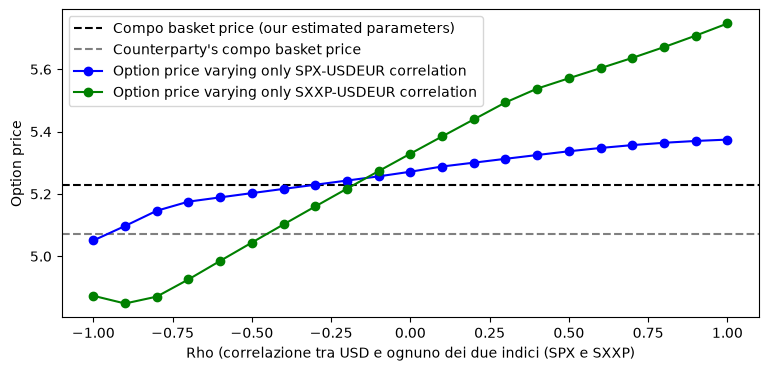

In [182]:
price_range_1 = []
price_range_2 = []
print(corr_m)
corr_m_i = corr_m.copy(deep=True)
rho_range = np.arange(-1, 1.1, 0.1)

# Visualizziamo la variazione nel fwd al variare della correlazione tra USD e SPX
plt.figure(figsize=(9, 4))
plt.axhline(put_basket_price*100, color='black', linestyle='--', label='Compo basket price (our estimated parameters)')
plt.axhline(basket_price_cpty*100, color='grey', linestyle='--', label="Counterparty's compo basket price")

# imposing the implied correlation from the counterparty on the historically estimated correlation matrix
ticker1 = 'EUUS F160 Curncy'
ticker2 = 'SPX Index'
ticker3 = 'SXXP Index'
# calculate price by changing the correlation between SPX and the currency keeping the rest still
for rho_i in rho_range:
    # change corr between spx and currency
    corr_m_i.loc[ticker1,ticker2] = rho_i
    corr_m_i.loc[ticker2,ticker1] = rho_i
    price = basket_option_pricer_MC(weights, strike, mu, r_disc, vol, T, num_assets, corr_m_i, sim_num, style, seed)
    price_range_1.append(price)

# reset the initial corr matrix
corr_m_i = corr_m.copy(deep=True)
print(corr_m)
# calculate price by changing the correlation between SXXP and the currency keeping the rest still
for rho_i in rho_range:
    # change corr between sxxp and currency
    corr_m_i.loc[ticker1,ticker3] = rho_i
    corr_m_i.loc[ticker3,ticker1] = rho_i
    price = basket_option_pricer_MC(weights, strike, mu, r_disc, vol, T, num_assets, corr_m_i, sim_num, style, seed)
    price_range_2.append(price)

# Visualizziamo la variazione nel fwd al variare della correlazione tra USD e SPX
plt.plot(rho_range, np.array(price_range_1) * 100, color='blue', marker='o', label='Option price varying only SPX-USDEUR correlation')
plt.plot(rho_range, np.array(price_range_2) * 100, color='green', marker='o', label='Option price varying only SXXP-USDEUR correlation')
plt.xlabel('Rho (correlazione tra USD e ognuno dei due indici (SPX e SXXP)')
plt.ylabel('Option price')
plt.legend()
plt.show()

In [183]:
# Build a two-correlation price surface, keeping the index-index correlation fixed.
ticker_spx = "SPX Index"
ticker_sxxp = "SXXP Index"
ticker_fx = "EUUS F160 Curncy"
rho_grid_3d = rho_range
surface_base_corr = corr_m.copy(deep=True)
price_surface = np.full((len(rho_grid_3d), len(rho_grid_3d)), np.nan)
valid_surface = np.zeros(price_surface.shape, dtype=bool)

for j, rho_sxxp_fx in enumerate(rho_grid_3d):
    for i, rho_spx_fx in enumerate(rho_grid_3d):
        corr_candidate = surface_base_corr.copy(deep=True)
        corr_candidate.loc[ticker_spx, ticker_fx] = rho_spx_fx
        corr_candidate.loc[ticker_fx, ticker_spx] = rho_spx_fx
        corr_candidate.loc[ticker_sxxp, ticker_fx] = rho_sxxp_fx
        corr_candidate.loc[ticker_fx, ticker_sxxp] = rho_sxxp_fx

        if np.linalg.eigvalsh(corr_candidate.to_numpy()).min() < -1e-10:
            continue

        valid_surface[j, i] = True
        grid_payoffs = calc_basket_payoff(
            weights,
            strike,
            mu,
            vol,
            T,
            sim_num,
            num_assets,
            corr_candidate,
            style,
            seed,
        )
        price_surface[j, i] = np.mean(grid_payoffs) * np.exp(-r_disc * T) * 100

if not valid_surface.any():
    raise ValueError("No positive-semidefinite correlation matrices in the selected grid.")

counterparty_price_pct = basket_price_cpty * 100
valid_prices = price_surface[valid_surface]
counterparty_in_range = (
    valid_prices.min() <= counterparty_price_pct <= valid_prices.max()
)

import plotly.graph_objects as go

surface_z = np.where(valid_surface, price_surface, np.nan)
counterparty_z = np.where(
    valid_surface,
    counterparty_price_pct,
    np.nan,
)

fig = go.Figure()

fig.add_trace(go.Surface(
    x=rho_grid_3d,
    y=rho_grid_3d,
    z=surface_z,
    colorscale="Viridis",
    colorbar=dict(title="Option price (%)"),
    name="Option-price surface",
    connectgaps=False,
    hovertemplate=(
        "SPX-USDEUR: %{x:.2f}<br>"
        "SXXP-USDEUR: %{y:.2f}<br>"
        "Option price: %{z:.3f}%<extra></extra>"
    ),
))

fig.add_trace(go.Surface(
    x=rho_grid_3d,
    y=rho_grid_3d,
    z=counterparty_z,
    colorscale=[
        [0, "rgb(110,110,110)"],
        [1, "rgb(110,110,110)"],
    ],
    opacity=0.28,
    showscale=False,
    name="Counterparty price",
    connectgaps=False,
    hovertemplate="Counterparty price: %{z:.3f}%<extra></extra>",
))

fig.add_trace(go.Scatter3d(
    x=[surface_base_corr.loc[ticker_spx, ticker_fx]],
    y=[surface_base_corr.loc[ticker_sxxp, ticker_fx]],
    z=[put_basket_price * 100],
    mode="markers+text",
    marker=dict(size=7, color="red", symbol="diamond"),
    text=["Historical estimate"],
    textposition="top center",
    name="Historical estimate",
    hovertemplate=(
        "SPX-USDEUR: %{x:.2f}<br>"
        "SXXP-USDEUR: %{y:.2f}<br>"
        "Option price: %{z:.3f}%<extra></extra>"
    ),
))
counterparty_plane = np.full(
    price_surface.shape,
    counterparty_price_pct,
    dtype=float,
)
counterparty_plane[~valid_surface] = np.nan

fig.add_trace(go.Surface(
    x=rho_grid_3d,
    y=rho_grid_3d,
    z=counterparty_plane,
    colorscale=[
        [0, "rgb(220,40,40)"],
        [1, "rgb(220,40,40)"],
    ],
    opacity=0.35,
    showscale=False,
    name=f"Counterparty price ({counterparty_price_pct:.2f}%)",
    connectgaps=False,
    hovertemplate="Counterparty price: %{z:.3f}%<extra></extra>",
))
fig.update_layout(
    title=(
        "Basket option price sensitivity to both correlations"
        f" — counterparty within sampled range: {counterparty_in_range}"
    ),
    scene=dict(
        xaxis_title="SPX-USDEUR correlation",
        yaxis_title="SXXP-USDEUR correlation",
        zaxis_title="Option price (%)",
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.1)),
    ),
    margin=dict(l=0, r=0, t=55, b=0),
)

fig.show()

# <a id='toc5_'></a>[Conclusions](#toc0_)
1. DLIB prices using a quanto adjustment, when we select EUR as the pricing currency the adjustment is on the USD asset as expected;
2. Even if the pricing currency is EUR DLIB does use the EUR curve implied by the FX forward on USDEUR. DLIB is assuming that collateral is exchanged in USD while we position ourself as using collateral in EUR. Definitino of collateral currency in the CSA is the determinant for the curve used in discounting;
3. The impact of changing the collateral currency is explained by the basis, in particular the option price under USD collateral vs EUR collateral differs by $exp(b*T)$ where b is the basis and T is time to expiry;
4. A single index quanto option is equivalent to a vanilla option where:
    - the forward is adjusted with the correlation adjustment between the foreign currency and the index,
    - the discount curve used is the curve in local currency even if the asset is priced in foreign currency,
    - thsnks to above properties the quanto option on single index can be priced also via closed formula unders the B-S framework;
5. We are able to replicate the price from DLIB very closely. If we assume USD collateral:
    - the discount rate and expected payoff at expiry get closer to DLIB
    - we reduce the price difference vs DLIB from 19 basis points to 12 basis points
6. When pricing using a 3 factor model for the composite basket we get 5.28% vs 5.07% by the counterparty. The difference is plausible with differences in the unknown parameters, such as FX vol, correlations between indices and FX. As we can see from the charts, only by adjusting the correlation between the two indices and the FX we reach the option price from the counterparty under several combinations of such correlations.
